# Дерево решений с нуля и классификация пассажиров

Реализация дерева для числовых и категориальных признаков. Сравнение с Random Forest, подбор гиперпараметров, SHAP и LIME. В сохранённом прогоне F1 Random Forest на валидации — 0,957.

Учебная работа НИУ ВШЭ или Яндекс Практикума; исходные формулировки заданий принадлежат авторам курса.

**Воспроизводимость:** Часть примеров использует открытые UCI-наборы, часть — students.csv и учебную PostgreSQL БД. Доступ к БД не предоставляется. Параметры подключения читаются из переменных PGHOST, PGPORT, PGDATABASE, PGUSER, PGPASSWORD. При необходимости задайте PGSSLMODE.

Сохранённые результаты получены до публикации; полное обучение при подготовке репозитория не повторялось.


# **Домашнее задание 4 (pro): древесные алгоритмы**

### **Постановка задач**

### **Домашнее задание состоит из двух подзадач:**

**1. В  разделе 1 ваша задача:**
-  реализовать свое решающее дерево
- сравнить его со стандартной имплементацией из sklearn

Функции и классы дерева вы должны оформить в модуль `hw4_code_pro.py`.

**2. В разделе два ваша задача:** решить задачу бинарной классификации при помощи написанного Вами дерева, а также леса из sklearn, а после интерпретировать лучшие модели. Чуть точнее

- Извлечь данные из базы данных;
- Предобработать датасет;
- Обучить собственный класс DT, а также RF из `sklearn` в как базовом варианте (гиперпараметры по умолчанию), так и с подбором гиперпараметров;
- Интерпретировать алгоритмы при помощи LIME или SHAP.


### **Оценивание:**

- Как всегда оцениваются как код, так и ответы на вопросы. Если нет одного и/или другого, то часть баллов за соответствующее задание без колебаний снимается.
- Брать код из открытых источников позволительно. Следование культуре цитирования **обязательно.**
- Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов.
- Неэффективная реализация кода может негативно отразиться на оценке.

### **Формат сдачи:**
Задания сдаются через  anytask. Посылка должна содержать:
* Ноутбук в формате ipynb
* Модуль hw4_code_pro.py


### **Баллы:**

Суммарно за задание можно получить 10 основных баллов и 1 бонусный балло.

Оценка за ДЗ = min{ваш балл, 10}

Мягкий дедлайн: 29 января 23:59

**Продуктивной и интересной вам работы!**


In [ ]:
!pip install optuna
!pip install lime
!pip install shap
!pip install psycopg2-binary

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Colormap, ListedColormap
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, make_scorer, f1_score
from sklearn.base import BaseEstimator, ClassifierMixin
from scipy.stats import randint, uniform

import seaborn as sns
sns.set(style='whitegrid')

import psycopg2
import psycopg2.extras

import shap
import lime
from lime.lime_tabular import LimeTabularExplainer

import optuna

import pickle

import warnings
warnings.filterwarnings('ignore')

# **1. Решающие деревья своими руками (6 баллов)**

В этой части вам нужно реализовать свой класс для обучения решающего дерева в задаче бинарной классификации с возможностью обработки вещественных и категориальных признаков.

Всего за часть вы можете получить 6 основных баллов и 1 бонусный.

### **Задание 1. (1 балл)**

Реализуйте функцию find_best_split из модуля hw4_code_pro.py

**Формулы**

$$Q(R) = -\frac {|R_l|}{|R|}H(R_l) -\frac {|R_r|}{|R|}H(R_r)$$

$R$ — множество объектов,
$R_l$ и $R_r$ — объекты, попавшие в левое и правое поддерево,

$H(R) = 1-p_1^2-p_0^2$

$p_1$, $p_0$ — доля объектов класса 1 и 0 соответственно

**Указания:**
- Пороги, приводящие к попаданию в одно из поддеревьев пустого множества объектов, не рассматриваются.
- В качестве порогов, нужно брать среднее двух сосдених (при сортировке) значений признака
- Поведение функции в случае константного признака может быть любым.
- При одинаковых приростах Джини нужно выбирать минимальный сплит.

In [ ]:
def find_best_split(feature_vector, target_vector):
    """
    подаем: вектор признака и вектор целевой переменной

    возвращаем:
    :return thresholds: отсортированный по возрастанию вектор со всеми возможными порогами, по которым объекты можно
     разделить на две различные подвыборки, или поддерева
    :return ginis: вектор со значениями критерия Джини для каждого из порогов в thresholds len(ginis) == len(thresholds)
    :return threshold_best: оптимальный порог (число)
    :return gini_best: оптимальное значение критерия Джини (число)
    """
    # ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ

    x = np.asarray(feature_vector, dtype=float)
    y = np.asarray(target_vector, dtype=int)
    n = x.shape[0]

    if n <= 1:
      return np.array([]), np.array([]), None, None
    elif len(x) != len(y):
      print('Векторы не равны')

    order = np.argsort(x, kind="mergesort")
    x_sorted = x[order]
    y_sorted = y[order]

    diff = x_sorted[1:] != x_sorted[:-1] #значение признака изменилось - получаем индексы
    #если нигде нет изменения — порог не делит выборку и выдает “нет порогов”
    if not np.any(diff):
        return np.array([]), np.array([]), None, None

    #Пороги, приводящие к попаданию в одно из поддеревьев пустого множества объектов, не рассматриваются
    split_pos = np.nonzero(diff)[0] + 1 #получаем индексы с ненулевым diff, получаем позиции для разреза
    #В качестве порогов, нужно брать среднее двух сосдених (при сортировке) значений признака
    thresholds = (x_sorted[split_pos - 1] + x_sorted[split_pos]) / 2.0

    #суммарное количество единиц слева и справа от позиции для разрыва
    cumsum_ones = np.cumsum(y_sorted)
    left_ones = cumsum_ones[split_pos - 1]
    right_ones = cumsum_ones[-1] - left_ones

    #сколько объектов в каждой части
    left_n = split_pos.astype(float)
    right_n = (n - split_pos).astype(float)

    #доли класса
    p_left = left_ones / left_n
    p_right = right_ones / right_n

    #джини
    h_left = 1.0 - p_left**2 - (1.0 - p_left) ** 2
    h_right = 1.0 - p_right**2 - (1.0 - p_right) ** 2

    #Q = - (|Rl|/|R|) H(Rl) - (|Rr|/|R|) H(Rr)
    ginis = - (left_n / n) * h_left - (right_n / n) * h_right

    #При одинаковых приростах Джини выбираем минимальный сплит
    gini_best = np.max(ginis)
    best_idx = int(np.where(ginis == gini_best)[0][0]) #возвращает первый из всех индексов с максимумом
    threshold_best = float(thresholds[best_idx])

    return thresholds, ginis, threshold_best, float(gini_best)

### **Задание 2. (0.25 балла)**

Загрузите таблицу [students.csv](https://github.com/AnastasiyaMax/MLDS_ml_course_fall21/blob/main/hw/hw5_trees/students.csv). Это немного преобразованный датасет [User Knowledge](https://archive.ics.uci.edu/ml/datasets/User+Knowledge+Modeling).

В наборе данных:
- признаки объекта записаны в первых пяти столбцах;
- в последнем записана целевая переменная (класс: 0 или 1).

По этим данным, используя функцию из задания 1, постройте:
- пять кривых "порог — значение критерия Джини" для всех пяти признаков;
- scatter-графики "значение признака — класс" для всех пяти признаков;

In [ ]:
df = pd.read_csv('students.csv')
df.head()

    STG   SCG   STR   LPR   PEG  UNS
0  0.00  0.00  0.00  0.00  0.00    0
1  0.08  0.08  0.10  0.24  0.90    1
2  0.06  0.06  0.05  0.25  0.33    0
3  0.10  0.10  0.15  0.65  0.30    1
4  0.08  0.08  0.08  0.98  0.24    0

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 258 entries, 0 to 257
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   STG     258 non-null    float64
 1   SCG     258 non-null    float64
 2   STR     258 non-null    float64
 3   LPR     258 non-null    float64
 4   PEG     258 non-null    float64
 5   UNS     258 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 12.2 KB


**Информация по столбцам**

- STG - The degree of study time for goal object materails
- SCG - The degree of repetition number of user for goal object materails
- STR - The degree of study time of user for related objects with goal object
- LPR - The exam performance of user for related objects with goal object
- PEG - The exam performance of user for goal objects
- UNS - The knowledge level of user - *целевая переменная*

In [ ]:
feat = ['STG', 'SCG', 'STR', 'LPR', 'PEG']
y = df['UNS'].to_numpy().astype(int)

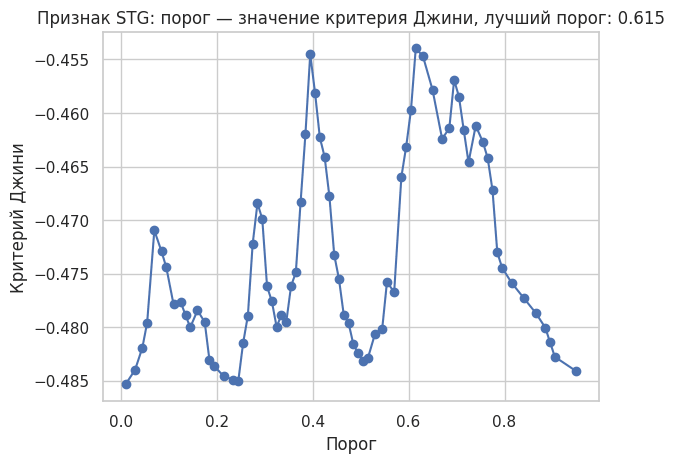

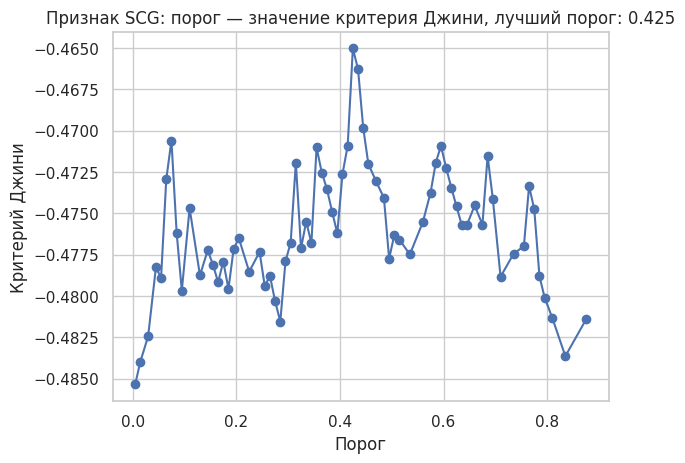

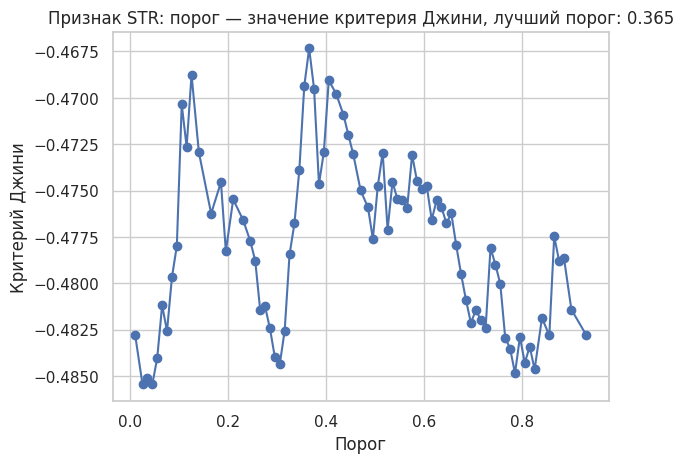

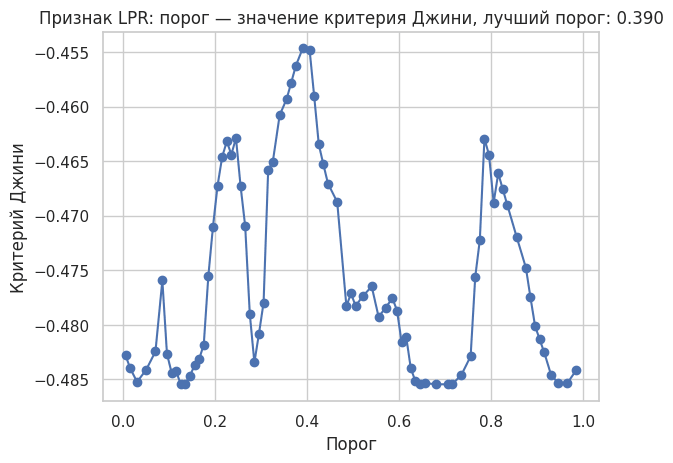

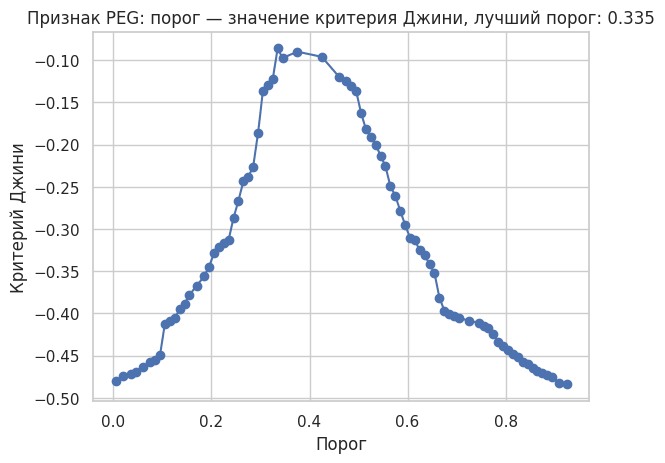

In [ ]:
for col in feat:
    x = df[col].to_numpy().astype(float)
    thresholds, ginis, threshold_best, gini_best = find_best_split(x, y)

    plt.figure()
    if thresholds.size == 0:
        plt.title(f'Признак {col} константный - нет допустимых порогов')
        plt.xlabel('Порог')
        plt.ylabel('Критерий Джини')
        plt.show()
        continue

    plt.plot(thresholds, ginis, marker='o', linestyle='-')
    plt.title(f'Признак {col}: порог — значение критерия Джини, лучший порог: {threshold_best:.3f}')
    plt.xlabel('Порог')
    plt.ylabel('Критерий Джини')

    plt.show()

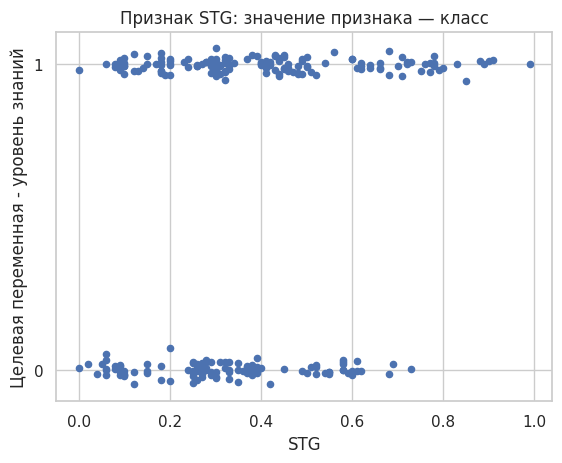

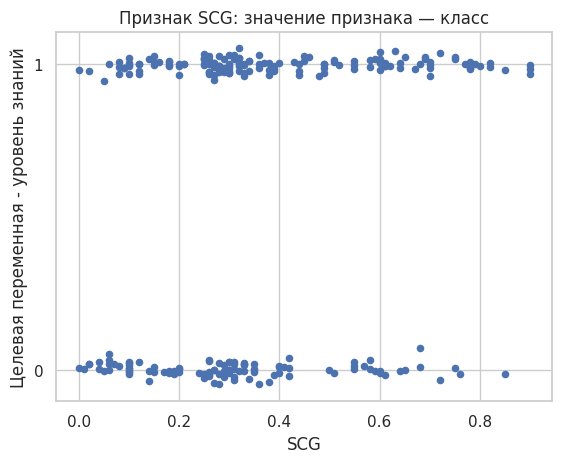

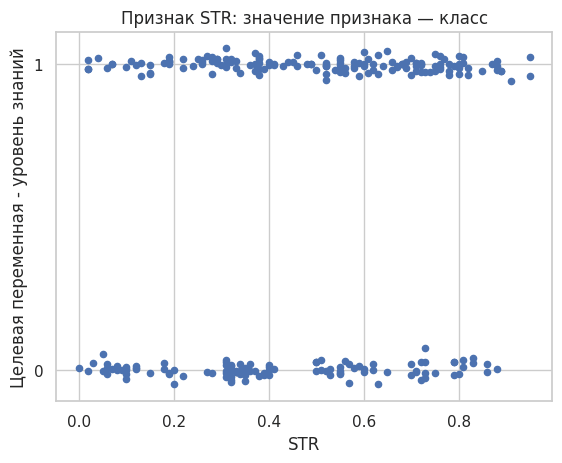

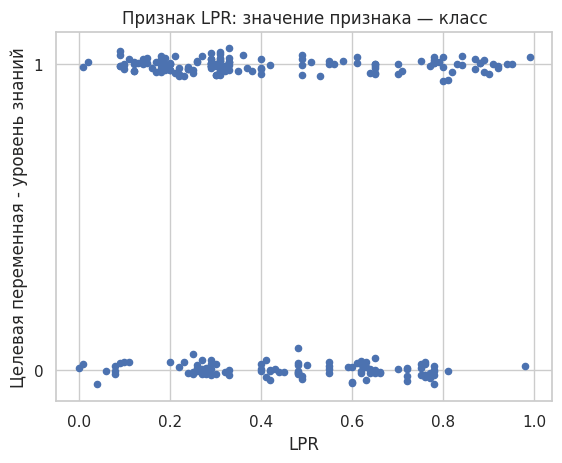

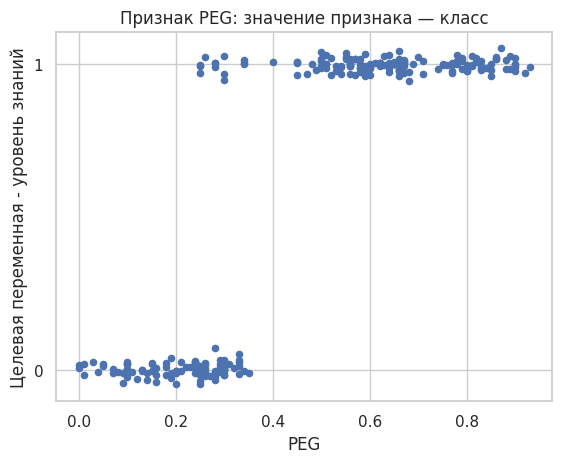

In [ ]:
#добавим шум по y, чтобы точки не слипались и можно было оценить плотность
rng = np.random.default_rng(77)
shum = rng.normal(0, 0.02, size=y.shape[0])

for col in feat:
    x = df[col].to_numpy().astype(float)

    plt.figure()
    plt.scatter(x, y + shum, s=20)
    plt.title(f'Признак {col}: значение признака — класс')
    plt.xlabel(col)
    plt.ylabel('Целевая переменная - уровень знаний')
    plt.yticks([0, 1])
    plt.show()

### **Задание 3. (0.6 балла)**

Проанализируйте построенные кривые. Ответьте на поставленные вопросы:
- По какому признаку нужно производить деление выборки на два поддерева? (0.15 балла)
- Согласуется ли этот результат с визуальной оценкой scatter-графиков? (0.15 балла)
- Как бы охарактеризовали вид кривой для "хороших" признаков, по которым выборка делится почти идеально? (0.15 балла)
- Чем отличаются кривые для признаков, по которым деление практически невозможно? (0.15 балла)

**Ответ:**

1) четкое разделение на 2 подгруппы дает признак PEG - The exam performance of user for goal objects - то есть то, насколько успешно сданы экзамены по целевым предметам, что звучит логично, это является наиболее показательным признаком
  - именно на графике этого признака значение Джини достигает числа значитльно более близкого к 0: -0.1, разбиение по PEG сильнее всего уменьшает неоднородность классов на следующем уровне
  - на остальных признаках это максимальное значение на несколько десятых меньше
2) Также возможность хорошо разделить по признаку PEG на две группы видна на scatter-графиках:
  - класс 0 почти весь при PEG ≈ 0–0.35, класс 1 ≈ 0.4–0.9
  - если мы проведем вертикальную линию, то она разделит на 2 группы максимально большинство объектов
  - в признаке LPR (успеваемость по другим связанным предметам) есть по верхней и нижней линии некоторые скопления, еще менее заметны они в других признаках, где распределение по горизонталям более однородное

3) Кривая, где ярко выражен пик; этот пик по значению Джини стремится к 0
4) кривая низкая, то естьь значение критерия почти не улучшается ни при каком пороге, нет ярко выраженного глобального пика, он может почти не отличаться от соседних точек, может быть много мелких локальных пиков. Мы можем наблюдать это на остальных признаках: максимумы есть, но они небольшие, кривая скачет, и scatter показывает, что классы сильно перемешаны почти по всему диапазону значений

Таким образом,
- по признаку PEG можно будет проводить первое разделение, а по другим признакам уточнять объекты около порога, например
- поскольку дерево в первом разделении может разделить очень хорошо по классам, то оно должно быть неглубоким
- вторым по влиянию признаком, скорее всего, будет  LPR - успеваемость по связанным с основными предметам, хотя там больше пересечений классов, нет однородного деления
- у других признаков более слабо выраженная связь с целевой перемнной, они дополняют и уточняют, то есть повторы и время учебы могут оказывать влияние, но они не такие показательные

### **Задание 4. (1.15 балла)**

В некоторых случаях необходимо анализировать код исполненного класса на предмет оптимальности и ошибок. Потренируйтесь в этом!

- Разберитесь с уже написанным кодом в классе DecisionTree модуля hw4_code_pro.py.
- Найдите ошибки в реализации метода \_fit_node.
- Напишите функцию \_predict_node.

**Примечание 1:**

Построение дерева осуществляется согласно базовому жадному алгоритму, предложенному в [лекции](https://github.com/esokolov/ml-course-hse/blob/master/2020-fall/lecture-notes/lecture07-trees.pdf) в разделе «Построение дерева».
- Для категориальных признаков выполняется преобразование, описанное в лекции в разделе «Учет категориальных признаков».

**Примечание 2:**

- Выбор лучшего разбиения необходимо производить по критерию Джини.
- Критерий останова: все объекты в листе относятся к одному классу или ни по одному признаку нельзя разбить выборку, чтобы Джини упал
- Ответ в листе: наиболее часто встречающийся класс в листе.


In [ ]:
class DecisionTree:
    def __init__(self, feature_types, max_depth=None, min_samples_split=None, min_samples_leaf=None):
        if np.any(list(map(lambda x: x != "real" and x != "categorical", feature_types))):
            raise ValueError("There is unknown feature type")

        self._tree = {}
        self._feature_types = feature_types
        self._max_depth = max_depth
        self._min_samples_split = min_samples_split
        self._min_samples_leaf = min_samples_leaf

    def _fit_node(self, sub_X, sub_y, node):
        if np.all(sub_y == sub_y[0]):  #исправление, так как критрий останова: в листе все объекты одного класса
            node["type"] = "terminal"
            node["class"] = sub_y[0]
            return

        p1 = np.mean(sub_y)
        q_parent = -(1.0 - p1**2 - (1.0 - p1)**2)

        feature_best, threshold_best, gini_best, split = None, None, None, None
        for feature in range(sub_X.shape[1]):  #исправление, чтобы не забыть первый признак
            feature_type = self._feature_types[feature]
            categories_map = {}

            if feature_type == "real":
                feature_vector = sub_X[:, feature]
            elif feature_type == "categorical":
                counts = Counter(sub_X[:, feature])
                clicks = Counter(sub_X[sub_y == 1, feature])
                ratio = {}
                for key, current_count in counts.items():
                    if key in clicks:
                        current_click = clicks[key]
                    else:
                        current_click = 0
                    ratio[key] = current_click / current_count #исправление, строим по доле объектов класса +1 среди объектов категории
                sorted_categories = [cat for cat, _ in sorted(ratio.items(), key=lambda x: x[1])]
                categories_map = {cat: i for i, cat in enumerate(sorted_categories)}

                feature_vector = np.array([categories_map[v] for v in sub_X[:, feature]]) #исправление, делаем числовой вектор вместо массива-объекта

            else:
                raise ValueError

            _, _, threshold, gini = find_best_split(feature_vector, sub_y)
            if threshold is None: #исправлено, проверка существует ли сплит вообще
                continue

            if gini_best is None or gini > gini_best:
                feature_best = feature
                gini_best = gini
                split = feature_vector < threshold

                if feature_type == "real":
                    threshold_best = threshold
                elif feature_type == "categorical": #неправильно написано название типа данных
                    threshold_best = list(map(lambda x: x[0],
                                              filter(lambda x: x[1] < threshold, categories_map.items())))
                else:
                    raise ValueError

        if (feature_best is None) or (gini_best <=q_parent):
            node["type"] = "terminal"
            node["class"] = Counter(sub_y).most_common(1)[0][0] #исправили, в лист теперь записывается класс, а не кортеж
            return

        node["type"] = "nonterminal"

        node["feature_split"] = feature_best
        if self._feature_types[feature_best] == "real":
            node["threshold"] = threshold_best
        elif self._feature_types[feature_best] == "categorical":
            node["categories_split"] = threshold_best
        else:
            raise ValueError
        node["left_child"], node["right_child"] = {}, {}
        self._fit_node(sub_X[split], sub_y[split], node["left_child"])
        self._fit_node(sub_X[np.logical_not(split)], sub_y[np.logical_not(split)], node["right_child"]) #исправление: правому Х должена соотвествовать своя часть y

    def _predict_node(self, x, node):
        # ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
        if node['type'] == 'terminal':
            return node['class']

        feature = node['feature_split']
        feature_type = self._feature_types[feature]

        if feature_type == 'real':
            if x[feature] < node['threshold']:
                return self._predict_node(x, node['left_child'])
            else:
                return self._predict_node(x, node['right_child'])

        elif feature_type == 'categorical':
            if x[feature] in node['categories_split']:
                return self._predict_node(x, node['left_child'])
            else:
                return self._predict_node(x, node['right_child'])

        else:
            raise ValueError("There is unknown feature type")

    def fit(self, X, y):
        self._fit_node(X, y, self._tree)

    def predict(self, X):
        predicted = []
        for x in X:
            predicted.append(self._predict_node(x, self._tree))
        return np.array(predicted)

### **Задание 5. (0.5 балла)**

Протестируйте свое решающее дерево на датасете [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom). Для этого:

- Скачайте таблицу agaricus-lepiota.data (из [Data Folder](https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/))
- Прочитайте данные с помощью pandas
- Примените к каждому столбцу LabelEncoder (из sklearn), чтобы преобразовать строковые имена категорий в натуральные числа.
- Обучите решающее дерево на половине случайно выбранных объектов (признаки в датасете категориальные)
- Сделайте предсказания для оставшейся половины.
- Вычислите accuracy (так как мы используем эту метрику и в силу задачи, нам не очень важно, что будет классом 1, а что — классом 0).  


У вас должно получиться значение accuracy, равное единице (или очень близкое к единице), и не очень глубокое дерево.

In [ ]:
# Ваш код здесь
URL_MUSHROOMS = 'https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data'
df_m = pd.read_csv(URL_MUSHROOMS, na_values=["?"], header=None)

df_m.head()

  0  1  2  3  4  5  6  7  8  9   ... 13 14 15 16 17 18 19 20 21 22
0  p  x  s  n  t  p  f  c  n  k  ...  s  w  w  p  w  o  p  k  s  u
1  e  x  s  y  t  a  f  c  b  k  ...  s  w  w  p  w  o  p  n  n  g
2  e  b  s  w  t  l  f  c  b  n  ...  s  w  w  p  w  o  p  n  n  m
3  p  x  y  w  t  p  f  c  n  n  ...  s  w  w  p  w  o  p  k  s  u
4  e  x  s  g  f  n  f  w  b  k  ...  s  w  w  p  w  o  e  n  a  g

[5 rows x 23 columns]

In [ ]:
df_m.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       8124 non-null   object
 1   1       8124 non-null   object
 2   2       8124 non-null   object
 3   3       8124 non-null   object
 4   4       8124 non-null   object
 5   5       8124 non-null   object
 6   6       8124 non-null   object
 7   7       8124 non-null   object
 8   8       8124 non-null   object
 9   9       8124 non-null   object
 10  10      8124 non-null   object
 11  11      5644 non-null   object
 12  12      8124 non-null   object
 13  13      8124 non-null   object
 14  14      8124 non-null   object
 15  15      8124 non-null   object
 16  16      8124 non-null   object
 17  17      8124 non-null   object
 18  18      8124 non-null   object
 19  19      8124 non-null   object
 20  20      8124 non-null   object
 21  21      8124 non-null   object
 22  22      8124 non-null   

In [ ]:
df_m.isna().sum()

0        0
1        0
2        0
3        0
4        0
5        0
6        0
7        0
8        0
9        0
10       0
11    2480
12       0
13       0
14       0
15       0
16       0
17       0
18       0
19       0
20       0
21       0
22       0
dtype: int64

In [ ]:
df_m = df_m.fillna("NA")

In [ ]:
encoders = {}
df_enc = df_m.copy()

for col in df_enc.columns:
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df_enc[col].astype(str))
    encoders[col] = le

y = df_enc.iloc[:, 0].to_numpy()
X = df_enc.iloc[:, 1:].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=77, shuffle=True, stratify=y)
feature_types = ['categorical'] * X_train.shape[1]
tree = DecisionTree(feature_types=feature_types)

tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print('accuracy =', round(acc, 3))

accuracy = 1.0


In [ ]:
def tree_depth(node):
    if node["type"] == "terminal":
        return 1
    return 1 + max(tree_depth(node["left_child"]), tree_depth(node["right_child"]))

print('Глубина дерева', tree_depth(tree._tree))

Глубина дерева 8


- Мы получили accuracy = 1.0 и не очень глубокое дерево (глубина = 8)
- Вероятно, есть сильно связанные с целевой переменной признаки, которые позволяют быстро и четко разделить данные по определенным правилам/закономрностям
- На каждом шаге выбирается разбиение, которое лучше всего уменьшает неоднородность по критерию Джини, поэтому дерево не уходит на большую глубину
- Дерево легко находит информативные признаки, по которым можно произвести наиболее эффективное разделение, поэтому мы видим идеальное качество на такой глубине

### **Задание 6. (бонус, 1 балл)**

Реализуйте в классе DecisionTree поддержку параметров max_depth, min_samples_split и min_samples_leaf по аналогии с DecisionTreeClassifier. Постройте графики зависимости качества предсказания в зависимости от этих параметров для набора данных tic-tac-toe (см. следующее задание).

In [ ]:
URL_TICTACTOE = 'https://archive.ics.uci.edu/ml/machine-learning-databases/tic-tac-toe/tic-tac-toe.data'
tic = pd.read_csv(URL_TICTACTOE, header=None)

tic.head()

   0  1  2  3  4  5  6  7  8         9
0  x  x  x  x  o  o  x  o  o  positive
1  x  x  x  x  o  o  o  x  o  positive
2  x  x  x  x  o  o  o  o  x  positive
3  x  x  x  x  o  o  o  b  b  positive
4  x  x  x  x  o  o  b  o  b  positive

In [ ]:
tic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 958 entries, 0 to 957
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       958 non-null    object
 1   1       958 non-null    object
 2   2       958 non-null    object
 3   3       958 non-null    object
 4   4       958 non-null    object
 5   5       958 non-null    object
 6   6       958 non-null    object
 7   7       958 non-null    object
 8   8       958 non-null    object
 9   9       958 non-null    object
dtypes: object(10)
memory usage: 75.0+ KB


In [ ]:
X_tic = tic.iloc[:, :-1]
y_raw = tic.iloc[:, -1]
y_tic = (y_raw == 'positive').astype(int).to_numpy()

In [ ]:
class DecisionTree:
    def __init__(self, feature_types, max_depth=None, min_samples_split=None, min_samples_leaf=None):
        if np.any(list(map(lambda x: x != "real" and x != "categorical", feature_types))):
            raise ValueError("There is unknown feature type")

        self._tree = {}
        self._feature_types = feature_types
        self._max_depth = max_depth
        self._min_samples_split = min_samples_split
        self._min_samples_leaf = min_samples_leaf

    #добавим округление для листов и сплитов
    def _to_int_threshold(self, val, n):
      if val is None:
          return None
      if isinstance(val, float):
          return int(np.ceil(val * n))
      return int(val)

    def _fit_node(self, sub_X, sub_y, node, depth=0):
      if self._max_depth is not None and depth >= self._max_depth:
            node['type'] = 'terminal'
            node['class'] = Counter(sub_y).most_common(1)[0][0]
            return

      if np.all(sub_y == sub_y[0]):
            node["type"] = "terminal"
            node["class"] = sub_y[0]
            return

      mss = self._to_int_threshold(self._min_samples_split, len(sub_y))
      if mss is not None and len(sub_y) < mss:
          node['type'] = 'terminal'
          node['class'] = Counter(sub_y).most_common(1)[0][0]
          return

      p1 = np.mean(sub_y)
      q_parent = -(1.0 - p1**2 - (1.0 - p1)**2)

      feature_best, threshold_best, gini_best, split = None, None, None, None
      for feature in range(sub_X.shape[1]):
          feature_type = self._feature_types[feature]
          categories_map = {}

          if feature_type == "real":
              feature_vector = sub_X[:, feature]
          elif feature_type == "categorical":
              counts = Counter(sub_X[:, feature])
              clicks = Counter(sub_X[sub_y == 1, feature])
              ratio = {}
              for key, current_count in counts.items():
                  if key in clicks:
                      current_click = clicks[key]
                  else:
                      current_click = 0
                  ratio[key] = current_click / current_count
              sorted_categories = [cat for cat, _ in sorted(ratio.items(), key=lambda x: x[1])]
              categories_map = {cat: i for i, cat in enumerate(sorted_categories)}

              feature_vector = np.array([categories_map[v] for v in sub_X[:, feature]])

          else:
              raise ValueError

          _, _, threshold, gini = find_best_split(feature_vector, sub_y)
          if threshold is None:
              continue

          split = feature_vector < threshold

          msl = self._to_int_threshold(self._min_samples_leaf, len(sub_y))
          if msl is not None:
              if split.sum() < msl or (~split).sum() < msl:
                  continue

          if gini_best is None or gini > gini_best:
              feature_best = feature
              gini_best = gini
              split_best = split

              if feature_type == "real":
                  threshold_best = threshold
              elif feature_type == "categorical":
                  threshold_best = list(map(lambda x: x[0], filter(lambda x: x[1] < threshold, categories_map.items())))
              else:
                  raise ValueError

      if (feature_best is None) or (gini_best <=q_parent):
          node["type"] = "terminal"
          node["class"] = Counter(sub_y).most_common(1)[0][0]
          return

      node["type"] = "nonterminal"

      node["feature_split"] = feature_best

      if self._feature_types[feature_best] == "real":
          node["threshold"] = threshold_best
      elif self._feature_types[feature_best] == "categorical":
          node["categories_split"] = threshold_best
      else:
          raise ValueError

      node["left_child"], node["right_child"] = {}, {}
      self._fit_node(sub_X[split_best], sub_y[split_best], node["left_child"], depth + 1)
      self._fit_node(sub_X[np.logical_not(split_best)], sub_y[np.logical_not(split_best)], node["right_child"], depth + 1)

    def _predict_node(self, x, node):
        # ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
        if node['type'] == 'terminal':
            return node['class']

        feature = node['feature_split']
        feature_type = self._feature_types[feature]

        value = x.iloc[feature] if hasattr(x, "iloc") else x[feature]

        if feature_type == 'real':
            if value < node['threshold']:
                return self._predict_node(x, node['left_child'])
            else:
                return self._predict_node(x, node['right_child'])

        elif feature_type == 'categorical':
            if value in node['categories_split']:
                return self._predict_node(x, node['left_child'])
            else:
                return self._predict_node(x, node['right_child'])

        else:
            raise ValueError("There is unknown feature type")

    def fit(self, X, y):
        self._fit_node(X, y, self._tree, depth=0)

    def predict(self, X):
        predicted = []
        for x in X:
            predicted.append(self._predict_node(x, self._tree))
        return np.array(predicted)


In [ ]:
X_tic_enc = X_tic.copy()
encoders = {}

for col in X_tic_enc.columns:
    le = LabelEncoder()
    X_tic_enc[col] = le.fit_transform(X_tic_enc[col].astype(str))
    encoders[col] = le

X_tic = X_tic_enc.to_numpy()
feature_types_tic = ['categorical'] * X_tic.shape[1]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_tic, y_tic, test_size=0.3, random_state=42, stratify=y_tic)

def evaluate_tree(max_depth=None, min_samples_split=2, min_samples_leaf=1):
    tree = DecisionTree(
        feature_types=feature_types_tic,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf
    )
    tree.fit(X_train, y_train)
    y_pred = tree.predict(X_test)
    return accuracy_score(y_test, y_pred)

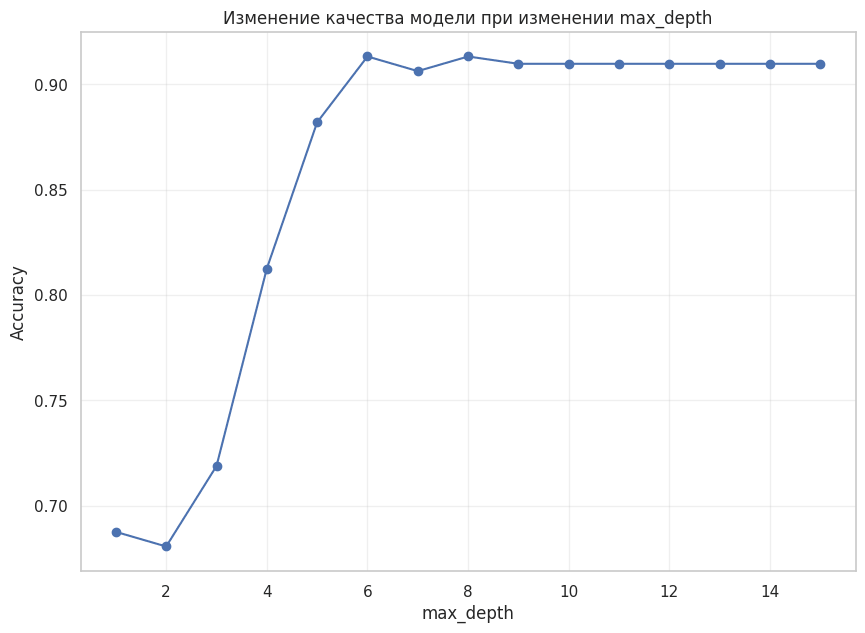

Лучший max_depth: 6 Accuracy: 0.9131944444444444


In [ ]:
depth_val = list(range(1, 16))
depth_sc = []

for d in depth_val:
    acc = evaluate_tree(max_depth=d, min_samples_split=2, min_samples_leaf=1)
    depth_sc.append(acc)

plt.figure(figsize=(10, 7))
plt.plot(depth_val, depth_sc, marker='o')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Изменение качества модели при изменении max_depth')
plt.grid(True, alpha=0.3)
plt.show()

print('Лучший max_depth:', depth_val[int(np.argmax(depth_sc))],
      'Accuracy:', max(depth_sc))

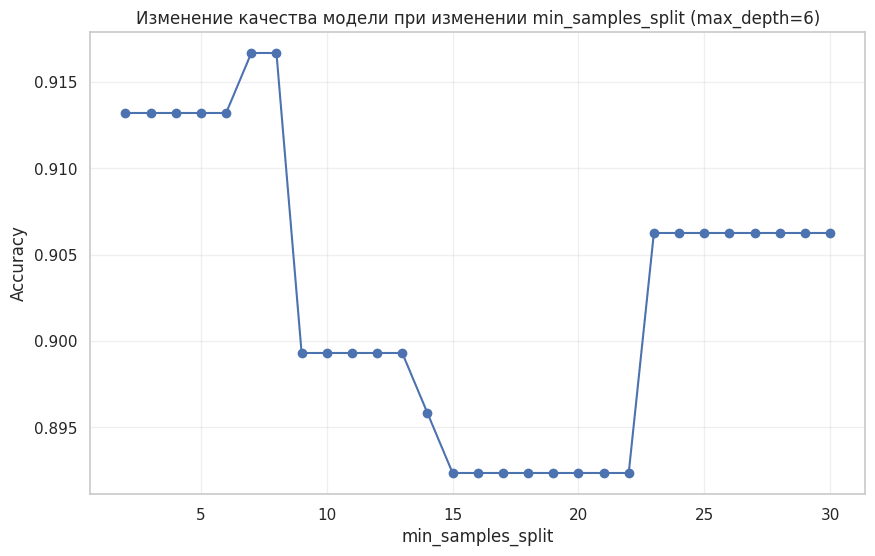

Лучший min_samples_split: 7 Accuracy: 0.9166666666666666


In [ ]:
best_depth_for_mss = depth_val[int(np.argmax(depth_sc))]

mss_val = list(range(2, 31))
mss_sc = []

for mss in mss_val:
    acc = evaluate_tree(max_depth=best_depth_for_mss, min_samples_split=mss, min_samples_leaf=1)
    mss_sc.append(acc)

plt.figure(figsize=(10, 6))
plt.plot(mss_val, mss_sc, marker='o')
plt.xlabel('min_samples_split')
plt.ylabel('Accuracy')
plt.title(f'Изменение качества модели при изменении min_samples_split (max_depth={best_depth_for_mss})')
plt.grid(True, alpha=0.3)
plt.show()

print('Лучший min_samples_split:', mss_val[int(np.argmax(mss_sc))],
      'Accuracy:', max(mss_sc))

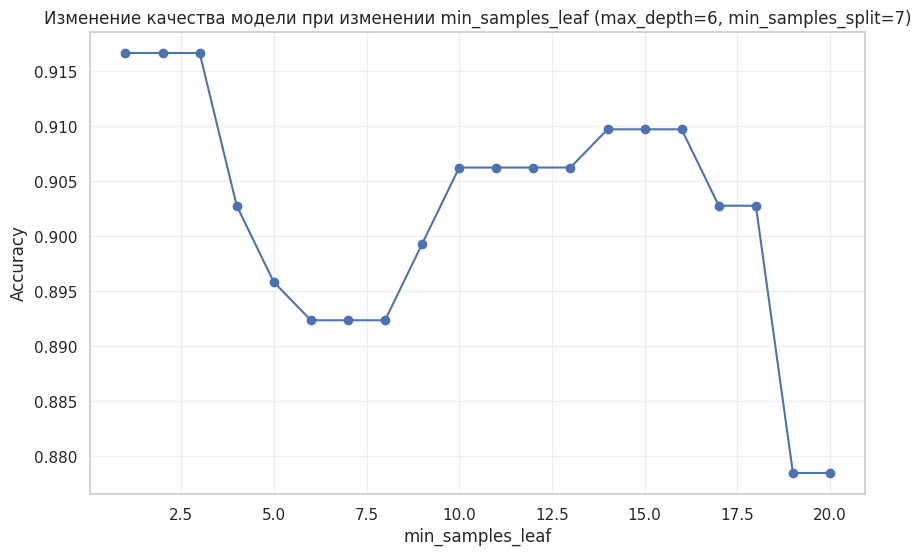

Лучший min_samples_leaf: 1 Accuracy: 0.9166666666666666


In [ ]:
best_mss_for_msl = mss_val[int(np.argmax(mss_sc))]

msl_val = list(range(1, 21))
msl_sc = []

for msl in msl_val:
    acc = evaluate_tree(
        max_depth=best_depth_for_mss,
        min_samples_split=best_mss_for_msl,
        min_samples_leaf=msl
    )
    msl_sc.append(acc)

plt.figure(figsize=(10, 6))
plt.plot(msl_val, msl_sc, marker='o')
plt.xlabel('min_samples_leaf')
plt.ylabel('Accuracy')
plt.title(f'Изменение качества модели при изменении min_samples_leaf (max_depth={best_depth_for_mss}, min_samples_split={best_mss_for_msl})')
plt.grid(True, alpha=0.3)
plt.show()

print('Лучший min_samples_leaf:', msl_val[int(np.argmax(msl_sc))],
      'Accuracy:', max(msl_sc))

- max_depth ограничивает глубину дерева, то есть количество разбиений по определенным правилам, min_samples_split и min_samples_leaf отвечают за количество объектов в узлах и листьях
- на графике с max_depth качество резко растет с 3 разбиения, мы достигаем максимума на 6, а далее получаем плато примерно у значения 0.91, то есть 6 закономерностей достаточно, для того чтобы уловить связь и хорошо распределить данные без подгонки под шум
- график с min_samples_split ступеньками, так как он дискретный, при изменении значения некоторые узлы перестают делиться и структура дерева меняется скачками, лучшее значение при параметре равном 7, при меньшем модет быть переобучение, если значение слишком большое - недообучение
- график min_samples_leaf - в данном случае регуляризация и настройка leaf ухудшает качество, то есть задача требует выделения более редких комбинаций признаков, важно не потерять частные правила

### **Задание 7. (2 балла)**

**1. Загрузите следующие наборы данных** (напомним, что pandas умеет загружать файлы по url, в нашем случае это файл \*.data), предварительно ознакомившись с описанием признаков и целевой переменной в каждом из них (они записаны в Data Folder, в файле *.names):
* [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom) (загрузили в предыдущем пункте, классы записаны в нулевом столбце),
* [tic-tac-toe](https://archive.ics.uci.edu/dataset/101/tic+tac+toe+endgame) (классы записаны в последнем столбце)
* [cars](https://archive.ics.uci.edu/ml/datasets/Car+Evaluation) (классы записаны в последнем столбце, считаем что unacc, acc — это класс 0, good, vgood — класс 1)
* [nursery](https://archive.ics.uci.edu/ml/datasets/Nursery) (классы записаны в последнем столбце, считаем, что not_recom и recommend — класс 0, very_recom, priority, spec_prior — класс 1).

**2. Закодируйте категориальные признаки, использовав LabelEncoder.** С помощью cross_val_score (cv=10) оцените accuracy на каждом из этих наборов данных следующих алгоритмов:
* DecisionTree, считающий все признаки вещественными
* DecisionTree, считающий все признаки категориальными
* DecisionTree, считающий все признаки вещественными + one-hot-encoding всех признаков
* DecisionTreeClassifier из sklearn. Запишите результат в pd.DataFrame (по строкам — наборы данных, по столбцам — алгоритмы).

**Рекомендации:**
* Чтобы cross_val_score вычисляла точность, нужно передать scoring=make_scorer(accuracy_score), обе фукнции из sklearn.metrics.
* Если вам позволяет память (а она скорее всего позволяет), указывайте параметр sparse=False в OneHotEncoder (если вы, конечно, используете его). Иначе вам придется добиваться того, чтобы ваша реализация дерева умела работать с разреженными матрицами.

In [ ]:
URL_CARS      = 'https://archive.ics.uci.edu/ml/machine-learning-databases/car/car.data'
URL_NURSERY   = 'https://archive.ics.uci.edu/ml/machine-learning-databases/nursery/nursery.data'


In [ ]:
df_m = pd.read_csv(URL_MUSHROOMS, na_values=["?"], header=None)
df_m = df_m.fillna("NA")
X_m = df_m.iloc[:, 1:]
y_raw = df_m.iloc[:, 0]
y_m = (y_raw == 'p').astype(int)

In [ ]:
tic = pd.read_csv(URL_TICTACTOE, header=None)
X_tic = tic.iloc[:, :-1]
y_raw = tic.iloc[:, -1]
y_tic = (y_raw == 'positive').astype(int)

In [ ]:
car = pd.read_csv(URL_CARS, header=None)
X_c = car.iloc[:, :-1]
y_raw = car.iloc[:, -1]
y_c = y_raw.map(lambda v: 1 if v in ['good','vgood'] else 0).astype(int)

In [ ]:
nur = pd.read_csv(URL_NURSERY, header=None)
X_n = nur.iloc[:, :-1]
y_raw = nur.iloc[:, -1]
y_n = y_raw.map(lambda v: 1 if v in ['very_recom', 'priority', 'spec_prior'] else 0).astype(int)


In [ ]:
def label_encode_dataframe(X_df: pd.DataFrame):
    X_enc = X_df.copy()
    encoders = {}
    for col in X_enc.columns:
        le = LabelEncoder()
        X_enc[col] = le.fit_transform(X_enc[col].astype(str))
        encoders[col] = le
    return X_enc, encoders

In [ ]:
def cv_acc(
    X, y, feature_types, cv=10,
    max_depth=None, min_samples_split=2, min_samples_leaf=1,
    shuffle=True, random_state=77):

    X = np.asarray(X)
    y = np.asarray(y)

    skf = StratifiedKFold(n_splits=cv, shuffle=shuffle, random_state=random_state)
    scores = []

    for train_idx, test_idx in skf.split(X, y):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        model = DecisionTree(
            feature_types=feature_types,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf
        )

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        scores.append(acc)

    return np.array(scores)

Для написанного самостоятельно дерева была использована своя функция кросс-валидации, потому что cross_val_score из sklearn ожидает модель в формате sklearn-estimator. Эта функция следует той же логике, что и cross_val_score: выбор разбиений на фолды, обучение модели на трейне, предсказание на валидационной части и вычисление метрики accuracy на каждом фолде с последующим усреднением.

In [ ]:
datasets = {
    'mushrooms': (X_m, y_m),
    'tic-tac-toe': (X_tic, y_tic),
    'cars': (X_c, y_c),
    'nursery': (X_n, y_n),
}

results = []

for name, (X_df, y_series) in datasets.items():
    X_le_df, _ = label_encode_dataframe(X_df)
    X_le = X_le_df.to_numpy()
    y = np.asarray(y_series)

    n_features = X_le.shape[1]

    #все веществ
    scores_real = cv_acc(
        X_le, y,
        feature_types=['real'] * n_features,
        cv=10
    )

    #все категориальные
    scores_cat = cv_acc(
        X_le, y,
        feature_types=['categorical'] * n_features,
        cv=10
    )

    # ohe, все веществ
    try:
        ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
    except TypeError:
        ohe = OneHotEncoder(sparse=False, handle_unknown='ignore')

    X_ohe = ohe.fit_transform(X_df.astype(str))
    scores_real_ohe = cv_acc(
        X_ohe, y,
        feature_types=["real"] * X_ohe.shape[1],
        cv=10
    )

    #sklearn
    sk_clf = DecisionTreeClassifier(random_state=77)
    scores_sklearn = cross_val_score(sk_clf, X_le, y, cv=10, scoring=make_scorer(accuracy_score))

    results.append({
        'dataset': name,
        'DecisionTree вещественные': scores_real.mean(),
        'DecisionTree категориальные': scores_cat.mean(),
        'DecisionTree вещественные + one-hot': scores_real_ohe.mean(),
        'DecisionTreeClassifier': scores_sklearn.mean(),
    })

results_df = pd.DataFrame(results).set_index('dataset')
display(results_df.round(4))

             DecisionTree вещественные  DecisionTree категориальные  \
dataset                                                               
mushrooms                       1.0000                       1.0000   
tic-tac-toe                     0.8664                       0.9415   
cars                            0.9907                       0.9907   
nursery                         0.9997                       0.9997   

             DecisionTree вещественные + one-hot  DecisionTreeClassifier  
dataset                                                                   
mushrooms                                 1.0000                  0.9611  
tic-tac-toe                               0.9405                  0.7946  
cars                                      0.9878                  0.9433  
nursery                                   0.9997                  0.9997  

Качество модели зависит как от датасета, так и от вида признаков и способа их кодирования.

- модели с грибами: самостоятельно написанное дерево дает результат в 1, а из библиотеки немного хуже, так как DecisionTreeClassifier считывает label-encoded признаки как обычные числовые и считает, что между кодами категорий есть числовой порядок, подход из самостоятельного дерева более гибкий, так как оно строит свое упорядочивание категорий на каждом узле по доле класса 1 и ищет лучшее разделение
**То есть** для настоящих категориальных признаков самописный подход лучше отражает структуру данных, в данном случае зависимость от способа обработки призанков.
- модели nursery дают практически одинаковый результат на всех вариантах, а значит датасет почти идеально разделим сам по себе, то есть можно выделить явные правила для разделения и независимо от способа обработки признаков получить высокий результат. То есть этот датасет зависит в большей степени от данных, чем от модели.
- модели с машинами: данные должны быть хорошо разделимы по правилам, судя по accuracy дерева с вещественными и качественными признаками, one hot показал результат похуже, вероятно, так как он увеличивает число признаков, и дерево начинает строить чуть более дробные разбиения, которые на определенных фолдах дают худший результат, DecisionTreeClassifier показал качество хуже из-за искусственно упорядоченных кодов категорий
- модели с крестиками-ноликами: здесь качество зависит от способа обработки признаков, так как у них нет естественного порядка и они являются исключительно категориальными, поэтому качество лучше когда признаки считают категориальными или кодируют с ohe. По этому датасету особенно заметно, что важно правильно обрабатывать категориальные признаки.

### **Задание 8. (0.5 балла)**

Проанализируйте результаты эксперимента. Ответьте на вопросы:
- Одинаково ли для разных наборов данных ранжируются алгоритмы?
Порассуждайте, почему так происходит.
- Обратите внимание на значение признаков в разных наборах данных.
Присутствует ли в результатах какая-то компонента случайности?
- Если случайность есть, то можно ли повлиять на нее и улушить работу алгоритмов?

**Ответ:**

1. Ранжируемость алгоритмов зависит от датасета в том числе: в nursery все методы почти равны, в остальных есть отличия в большей или меньшей степени

почему?
- из-за вида признаков: какие-то категориальные признаки можно закодировать числами и это не отразится на качестве, а другие лучше оставлять категориальными
- из-за зависимости между признаками и целевой перменной: в некоторых случаях наблюдаем большую чувствительность к способу кодирования, в других подбор правил разделения древа полностью справляется с задачей независимо от обработки признака
-из-за степени разделимости класса: если классы почти идеально разделимы, различия между алгоритмами становятся маленькими, если нет - способ обработки может сильно влиять

2. случайность присутствует в разбиении на фолды при кросс-валидации, accuracy может измениться при изменении random_state; наличии редких категорий, которые влияют на качество фолдов по-разному; при одинаковом приросте критерия Джини при сплите может зависеть от порядка данных или категорий

3. можно:
- при фиксации random_state мы убираем случайность и делаем результаты воспроизводимыми
- повторять кросс-валидацию несколько раз с разными разбиениями, усреднять результаты, чтобы уменьшить влияние случайного разбиения
- правильно кодировать категориальные признаки:
  - обычный LabelEncoder + трактовка как вещественных признаков может ухудшать результат
  - категориальная обработка или ohe могут давать лучший результат
- подбор гиперпараметров: глубина  минимальный samples split минимальный samples leaf


# **2. Задача бинарной классификации реализованным деревом (4 балла)**

Всего за эту часть можно получить 4 балла.

В этом разделе вам необходимо решить задачу бинарной классификации самописным деревом и лесом из sklearn, а после интерпретировать лучшие модели. А именно:

- Извлечь данные из базы данных;
- Предобработать датасет;
- Обучить собственный класс DT и RF из `sklearn` в как базовом варианте (гиперпараметры по умолчанию), так и с подбором гиперпараметров;
- Интерпретировать алгоритмы при помощи LIME или SHAP.


### **Познакомимся с задачей: постановка**

У вас есть данные о полетах, обладающие следущими характеристиками:
- Для **каждого** клиента известна краткая информация о самом человеке, о типе билета и о рейсе, а также оценки клиента различным аспектам полета.
- Для **некоторых** клиентов известна их удовлетворенность полетом (satisfied или neutral or dissatisfied).

По данным необходимо обучить модель, предсказывающую удовлетворенность клиентов полетом. Итоговые предсказания нужно сделать для клиентов, **для которых ответ неизвестен.**

### **Получение данных:**

Компания держит все данные в облаке Яндекса в Postgresql. Данные разбиты на смысловые таблицы. Чтобы получить данные, вам необходимо подключиться к базе данных и добыть оттуда данные.

In [ ]:
!mkdir -p ~/.postgresql &&  wget "https://storage.yandexcloud.net/cloud-certs/CA.pem"      --output-document ~/.postgresql/root.crt &&  chmod 0600 ~/.postgresql/root.crt

### **Задание 9. Получение данных (0.5 балла)**

- Подключитесь к БД при помощи `psycopg2.connect()`
- Напишите SQL-запрос, объединяющий 3 нужные таблицы в одну
- Результат запроса поместите в `pd.DataFrame`. Индексом получившегося датафрейма сделайте столбец 'id'.

Список столбцов таблиц добудьте самостоятельно.


**Примечание:**
 Не забудьте закрыть соединение. Или открывайте соединение, используя менеджер контекста `with as`, который закроет его автоматически

##### **Схема БД**

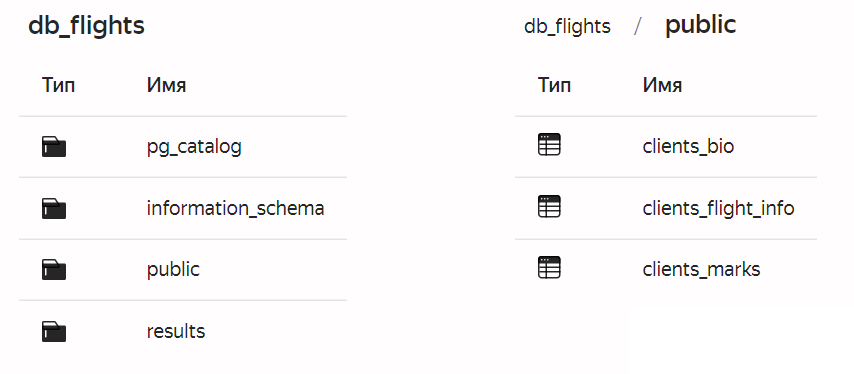

In [ ]:
import os

conn_params = dict(
    host=os.environ["PGHOST"],
    port=int(os.environ.get("PGPORT", "5432")),
    dbname=os.environ["PGDATABASE"],
    user=os.environ["PGUSER"],
    password=os.environ["PGPASSWORD"],
    sslmode=os.environ.get("PGSSLMODE", "verify-full"),
    target_session_attrs="read-write",
)

cols_sql = '''
SELECT table_name, column_name
FROM information_schema.columns
WHERE table_schema = 'public'
  AND table_name IN ('clients_bio','clients_flight_info','clients_marks')
ORDER BY table_name, ordinal_position;
'''

with psycopg2.connect(**conn_params) as conn:
    cols = pd.read_sql_query(cols_sql, conn)

display(cols)

             table_name                        column_name
0           clients_bio                                 id
1           clients_bio                             gender
2           clients_bio                                age
3   clients_flight_info                                 id
4   clients_flight_info                      Customer Type
5   clients_flight_info                     Type of Travel
6   clients_flight_info                              class
7   clients_flight_info                    Flight Distance
8   clients_flight_info         Departure Delay in Minutes
9   clients_flight_info           Arrival Delay in Minutes
10        clients_marks                                 id
11        clients_marks              Inflight wifi service
12        clients_marks  Departure/Arrival time convenient
13        clients_marks             Ease of Online booking
14        clients_marks                      Gate location
15        clients_marks                     Food and dri

In [ ]:
join_sql = """
SELECT
    b.id,
    b.gender,
    b.age,
    f."Customer Type",
    f."Type of Travel",
    f.class,
    f."Flight Distance",
    f."Departure Delay in Minutes",
    f."Arrival Delay in Minutes",
    m."Inflight wifi service",
    m."Departure/Arrival time convenient",
    m."Ease of Online booking",
    m."Gate location",
    m."Food and drink",
    m."Online boarding",
    m."Seat comfort",
    m."Inflight entertainment",
    m."On-board service",
    m."Leg room service",
    m."Baggage handling",
    m."Checkin service",
    m."Inflight service",
    m.cleanliness,
    m.satisfaction
FROM public.clients_bio b
JOIN public.clients_flight_info f ON b.id = f.id
JOIN public.clients_marks m ON b.id = m.id
ORDER BY b.id;
"""

with psycopg2.connect(**conn_params) as conn:
    df = pd.read_sql_query(join_sql, conn)

df = df.set_index('id')

In [ ]:
assert df.shape == (129_549, 23)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 129549 entries, 1 to 129880
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype 
---  ------                             --------------   ----- 
 0   gender                             129549 non-null  object
 1   age                                129549 non-null  object
 2   Customer Type                      129549 non-null  object
 3   Type of Travel                     129549 non-null  object
 4   class                              129549 non-null  object
 5   Flight Distance                    129549 non-null  object
 6   Departure Delay in Minutes         129549 non-null  object
 7   Arrival Delay in Minutes           129549 non-null  object
 8   Inflight wifi service              129549 non-null  object
 9   Departure/Arrival time convenient  129549 non-null  object
 10  Ease of Online booking             129549 non-null  object
 11  Gate location                      129549 non-null  objec

In [ ]:
df.head()

    gender   age      Customer Type   Type of Travel     class  \
id                                                               
1     Male  48.0  disloyal Customer  Business travel  Business   
2   Female  35.0     Loyal Customer  Business travel  Business   
3     Male  41.0     Loyal Customer  Business travel  Business   
4     Male  50.0     Loyal Customer  Business travel  Business   
5   Female  49.0     Loyal Customer  Business travel  Business   

   Flight Distance Departure Delay in Minutes Arrival Delay in Minutes  \
id                                                                       
1            821.0                        2.0                      5.0   
2            821.0                       26.0                     39.0   
3            853.0                        0.0                      0.0   
4           1905.0                        0.0                      0.0   
5           3470.0                        0.0                      1.0   

   Inflight wifi s

Разобьем датасет на тренировочную и тестовую части. Тестовую часть отложим надолго -- до самого конца этого ноутбука.

In [ ]:
df_train = df[df.satisfaction != '-']

df_train.tail()

        gender   age   Customer Type   Type of Travel     class  \
id                                                                
129874  Female  28.0  Loyal Customer  Personal Travel  Eco Plus   
129875  Female  55.0  Loyal Customer  Personal Travel  Eco Plus   
129878    Male  42.0  Loyal Customer  Personal Travel  Eco Plus   
129879    Male  50.0  Loyal Customer  Personal Travel  Eco Plus   
129880  Female  20.0  Loyal Customer  Personal Travel  Eco Plus   

       Flight Distance Departure Delay in Minutes Arrival Delay in Minutes  \
id                                                                           
129874           337.0                        0.0                      0.0   
129875           308.0                        0.0                      0.0   
129878           337.0                        6.0                     14.0   
129879           337.0                       31.0                     22.0   
129880           337.0                        0.0             

In [ ]:
assert df_train.shape == (103_644, 23)

In [ ]:
df_test = df[df.satisfaction == '-'].drop('satisfaction', axis=1)
df_test.head()

    gender   age      Customer Type   Type of Travel     class  \
id                                                               
17  Female  48.0     Loyal Customer  Personal Travel       Eco   
20  Female  42.0     Loyal Customer  Personal Travel       Eco   
35    Male  39.0     Loyal Customer  Business travel  Business   
44    Male  51.0     Loyal Customer  Business travel  Business   
49    Male  20.0  disloyal Customer  Business travel       Eco   

   Flight Distance Departure Delay in Minutes Arrival Delay in Minutes  \
id                                                                       
17           821.0                        0.0                      0.0   
20           821.0                        4.0                      0.0   
35          1672.0                       23.0                     17.0   
44          2077.0                        0.0                      1.0   
49           108.0                        0.0                     29.0   

   Inflight wifi s

In [ ]:
assert df_test.shape == (25_905, 22)

Разбиваем данные на трейн и валидацию. Не меняйте сид.

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(df_train.drop('satisfaction', axis=1), df_train.satisfaction, test_size=0.3, random_state=42)

In [ ]:
assert X_train.shape == (72_550, 22)
assert X_val.shape == (31_094, 22)

### **Задание 10 (0.25 балла)**

- Преобразуйте числовые столбцы в `float`. Проверьте, есть ли в датафрейме пропуски и выбросы (в том числе в категориальных признаках)
- Заполните пропуски в данных наиболее часто встречающимся значением.
Помните про правильность заполнения.
- Выведите основные статистики по числовым и категориальным столбцам таблицы
- Сделайте **текстовый** вывод о распределениях значений признаков

In [ ]:
num_cols = [
    "age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes",
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Inflight service",
    "cleanliness"
]

for c in num_cols:
    X_train[c] = pd.to_numeric(X_train[c], errors="coerce").astype(float)
    X_val[c] = pd.to_numeric(X_val[c], errors="coerce").astype(float)
    df_test[c] = pd.to_numeric(df_test[c], errors="coerce").astype(float)

In [ ]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 72550 entries, 32806 to 19805
Data columns (total 22 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             72550 non-null  object 
 1   age                                72365 non-null  float64
 2   Customer Type                      72550 non-null  object 
 3   Type of Travel                     72550 non-null  object 
 4   class                              72550 non-null  object 
 5   Flight Distance                    72504 non-null  float64
 6   Departure Delay in Minutes         72485 non-null  float64
 7   Arrival Delay in Minutes           72278 non-null  float64
 8   Inflight wifi service              72530 non-null  float64
 9   Departure/Arrival time convenient  72519 non-null  float64
 10  Ease of Online booking             72528 non-null  float64
 11  Gate location                      72532 non-null  floa

In [ ]:
X_val.info()

<class 'pandas.core.frame.DataFrame'>
Index: 31094 entries, 24136 to 80316
Data columns (total 22 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             31094 non-null  object 
 1   age                                31018 non-null  float64
 2   Customer Type                      31094 non-null  object 
 3   Type of Travel                     31094 non-null  object 
 4   class                              31094 non-null  object 
 5   Flight Distance                    31068 non-null  float64
 6   Departure Delay in Minutes         31075 non-null  float64
 7   Arrival Delay in Minutes           30961 non-null  float64
 8   Inflight wifi service              31082 non-null  float64
 9   Departure/Arrival time convenient  31084 non-null  float64
 10  Ease of Online booking             31083 non-null  float64
 11  Gate location                      31082 non-null  floa

In [ ]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25905 entries, 17 to 129877
Data columns (total 22 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             25905 non-null  object 
 1   age                                25851 non-null  float64
 2   Customer Type                      25905 non-null  object 
 3   Type of Travel                     25905 non-null  object 
 4   class                              25905 non-null  object 
 5   Flight Distance                    25883 non-null  float64
 6   Departure Delay in Minutes         25882 non-null  float64
 7   Arrival Delay in Minutes           25803 non-null  float64
 8   Inflight wifi service              25893 non-null  float64
 9   Departure/Arrival time convenient  25897 non-null  float64
 10  Ease of Online booking             25895 non-null  float64
 11  Gate location                      25898 non-null  float6

In [ ]:
def missing_report(df, name):
    miss = df.isna().sum()
    miss = miss[miss > 0].sort_values(ascending=False)
    print(f"\nПропуски в {name}:")
    if len(miss) == 0:
        print("Пропусков нет")
    else:
        display(pd.DataFrame({
            "missing_count": miss,
            "missing_share_%": (miss / len(df) * 100).round(3)
        }))

missing_report(X_train, "X_train")
missing_report(X_val, "X_val")
missing_report(df_test, "df_test")


Пропуски в X_train:


                                   missing_count  missing_share_%
Arrival Delay in Minutes                     272            0.375
age                                          185            0.255
Departure Delay in Minutes                    65            0.090
Flight Distance                               46            0.063
Seat comfort                                  36            0.050
Inflight service                              32            0.044
Departure/Arrival time convenient             31            0.043
Inflight entertainment                        27            0.037
Food and drink                                27            0.037
Leg room service                              26            0.036
On-board service                              25            0.034
Checkin service                               23            0.032
Online boarding                               23            0.032
Ease of Online booking                        22            0.030
Baggage ha


Пропуски в X_val:


                                   missing_count  missing_share_%
Arrival Delay in Minutes                     133            0.428
age                                           76            0.244
Flight Distance                               26            0.084
Departure Delay in Minutes                    19            0.061
Inflight service                              17            0.055
Inflight entertainment                        15            0.048
Online boarding                               14            0.045
Inflight wifi service                         12            0.039
Gate location                                 12            0.039
Ease of Online booking                        11            0.035
Checkin service                               11            0.035
Departure/Arrival time convenient             10            0.032
Baggage handling                              10            0.032
Leg room service                              10            0.032
cleanlines


Пропуски в df_test:


                                   missing_count  missing_share_%
Arrival Delay in Minutes                     102            0.394
age                                           54            0.208
Departure Delay in Minutes                    23            0.089
Flight Distance                               22            0.085
Baggage handling                              16            0.062
Food and drink                                15            0.058
Inflight service                              14            0.054
On-board service                              12            0.046
Inflight wifi service                         12            0.046
Ease of Online booking                        10            0.039
Leg room service                              10            0.039
Online boarding                                9            0.035
Checkin service                                8            0.031
Departure/Arrival time convenient              8            0.031
Gate locat

In [ ]:
cat_cols = ["gender", "Customer Type", "Type of Travel", "class"]

for c in cat_cols:
  print()
  print(X_train[c].value_counts(dropna=False).head(20))
  print()
  print(X_val[c].value_counts(dropna=False).head(20))
  print()
  print(df_test[c].value_counts(dropna=False).head(20))


gender
Female    36738
Male      35812
Name: count, dtype: int64

gender
Female    15852
Male      15242
Name: count, dtype: int64

gender
Female    13136
Male      12769
Name: count, dtype: int64

Customer Type
Loyal Customer       59314
disloyal Customer    13186
nan                     50
Name: count, dtype: int64

Customer Type
Loyal Customer       25341
disloyal Customer     5737
nan                     16
Name: count, dtype: int64

Customer Type
Loyal Customer       21108
disloyal Customer     4786
nan                     11
Name: count, dtype: int64

Type of Travel
Business travel    49992
Personal Travel    22504
nan                   54
Name: count, dtype: int64

Type of Travel
Business travel    21431
Personal Travel     9629
nan                   34
Name: count, dtype: int64

Type of Travel
Business travel    17982
Personal Travel     7910
nan                   13
Name: count, dtype: int64

class
Business    34574
Eco         32668
Eco Plus     5243
nan            65
Name: 

In [ ]:
for df_part in [X_train, X_val, df_test]:
    for c in cat_cols:
        df_part[c] = df_part[c].replace("nan", np.nan)

In [ ]:
rating_cols = [c for c in num_cols if c not in ["age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]]

def rating_outliers_report(df, name, rating_cols):
    out = {}
    for r in rating_cols:
        bad = df[r].dropna()
        bad = bad[(bad < 0) | (bad > 5)]
        if len(bad) > 0:
            out[r] = len(bad)

    print(f"\nВыбросы в рейтинговых признаках в {name} (вне [0, 5]):")
    print(out if len(out) > 0 else "Не обнаружены")

rating_outliers_report(X_train, "X_train", rating_cols)
rating_outliers_report(X_val, "X_val", rating_cols)
rating_outliers_report(df_test, "df_test", rating_cols)


Выбросы в рейтинговых признаках в X_train (вне [0, 5]):
{'Inflight wifi service': 16, 'Departure/Arrival time convenient': 20, 'Ease of Online booking': 17, 'Gate location': 18, 'Food and drink': 14, 'Online boarding': 26, 'Seat comfort': 22, 'Inflight entertainment': 16, 'On-board service': 17, 'Leg room service': 26, 'Baggage handling': 17, 'Checkin service': 25, 'Inflight service': 27, 'cleanliness': 15}

Выбросы в рейтинговых признаках в X_val (вне [0, 5]):
{'Inflight wifi service': 10, 'Departure/Arrival time convenient': 12, 'Ease of Online booking': 6, 'Gate location': 14, 'Food and drink': 5, 'Online boarding': 4, 'Seat comfort': 7, 'Inflight entertainment': 4, 'On-board service': 6, 'Leg room service': 10, 'Baggage handling': 5, 'Checkin service': 6, 'Inflight service': 6, 'cleanliness': 5}

Выбросы в рейтинговых признаках в df_test (вне [0, 5]):
{'Inflight wifi service': 8, 'Departure/Arrival time convenient': 7, 'Ease of Online booking': 7, 'Gate location': 11, 'Food and dr

In [ ]:
def numeric_checks(df, name):
    checks = {
        "age < 0": int((df["age"] < 0).sum()),
        "age > 120": int((df["age"] > 120).sum()),
        "Flight Distance < 0": int((df["Flight Distance"] < 0).sum()),
        "Departure Delay in Minutes < 0": int((df["Departure Delay in Minutes"] < 0).sum()),
        "Arrival Delay in Minutes < 0": int((df["Arrival Delay in Minutes"] < 0).sum()),
    }
    print(f"\nПроверка в датасете {name}:")
    print(checks)

numeric_checks(X_train, "X_train")
numeric_checks(X_val, "X_val")
numeric_checks(df_test, "df_test")


Проверка в датасете X_train:
{'age < 0': 0, 'age > 120': 202, 'Flight Distance < 0': 0, 'Departure Delay in Minutes < 0': 0, 'Arrival Delay in Minutes < 0': 0}

Проверка в датасете X_val:
{'age < 0': 0, 'age > 120': 85, 'Flight Distance < 0': 0, 'Departure Delay in Minutes < 0': 0, 'Arrival Delay in Minutes < 0': 0}

Проверка в датасете df_test:
{'age < 0': 0, 'age > 120': 83, 'Flight Distance < 0': 0, 'Departure Delay in Minutes < 0': 0, 'Arrival Delay in Minutes < 0': 0}


In [ ]:
def iqr_outliers_report(df, num_cols):
    rows = []
    for c in num_cols:
        x = df[c].dropna()
        q1 = x.quantile(0.25)
        q3 = x.quantile(0.75)
        iqr = q3 - q1
        low = q1 - 1.5 * iqr
        high = q3 + 1.5 * iqr
        n_out = ((x < low) | (x > high)).sum()
        rows.append({
            "column": c,
            "q1": q1,
            "q3": q3,
            "iqr": iqr,
            "low_bound": low,
            "high_bound": high,
            "n_outliers": int(n_out)
        })
    return pd.DataFrame(rows).sort_values("n_outliers", ascending=False)

iqr_report_train = iqr_outliers_report(X_train, num_cols)
display(iqr_report_train)

                               column     q1      q3     iqr  low_bound  \
2          Departure Delay in Minutes    0.0    12.0    12.0      -18.0   
3            Arrival Delay in Minutes    0.0    13.0    13.0      -19.5   
15                    Checkin service    3.0     4.0     1.0        1.5   
1                     Flight Distance  413.0  1744.0  1331.0    -1583.5   
0                                 age   27.0    51.0    24.0       -9.0   
9                     Online boarding    2.0     4.0     2.0       -1.0   
13                   Leg room service    2.0     4.0     2.0       -1.0   
16                   Inflight service    3.0     5.0     2.0        0.0   
5   Departure/Arrival time convenient    2.0     4.0     2.0       -1.0   
7                       Gate location    2.0     4.0     2.0       -1.0   
14                   Baggage handling    3.0     5.0     2.0        0.0   
10                       Seat comfort    2.0     5.0     3.0       -2.5   
6              Ease of On

In [ ]:
iqr_report_val = iqr_outliers_report(X_val, num_cols)
display(iqr_report_val)

                               column     q1      q3     iqr  low_bound  \
2          Departure Delay in Minutes    0.0    12.0    12.0      -18.0   
3            Arrival Delay in Minutes    0.0    13.0    13.0      -19.5   
15                    Checkin service    3.0     4.0     1.0        1.5   
1                     Flight Distance  417.0  1744.0  1327.0    -1573.5   
0                                 age   27.0    51.0    24.0       -9.0   
7                       Gate location    2.0     4.0     2.0       -1.0   
13                   Leg room service    2.0     4.0     2.0       -1.0   
5   Departure/Arrival time convenient    2.0     4.0     2.0       -1.0   
4               Inflight wifi service    2.0     4.0     2.0       -1.0   
6              Ease of Online booking    2.0     4.0     2.0       -1.0   
16                   Inflight service    3.0     5.0     2.0        0.0   
12                   On-board service    2.0     4.0     2.0       -1.0   
17                       

In [ ]:
iqr_report_test = iqr_outliers_report(df_test, num_cols)
display(iqr_report_test)

                               column     q1      q3     iqr  low_bound  \
2          Departure Delay in Minutes    0.0    12.0    12.0      -18.0   
3            Arrival Delay in Minutes    0.0    13.0    13.0      -19.5   
15                    Checkin service    3.0     4.0     1.0        1.5   
1                     Flight Distance  414.0  1747.0  1333.0    -1585.5   
0                                 age   27.0    51.0    24.0       -9.0   
10                       Seat comfort    2.0     5.0     3.0       -2.5   
8                      Food and drink    2.0     4.0     2.0       -1.0   
7                       Gate location    2.0     4.0     2.0       -1.0   
16                   Inflight service    3.0     5.0     2.0        0.0   
5   Departure/Arrival time convenient    2.0     4.0     2.0       -1.0   
4               Inflight wifi service    2.0     4.0     2.0       -1.0   
17                        cleanliness    2.0     4.0     2.0       -1.0   
11             Inflight e

In [ ]:
# мода по train
fill_values = {}
for c in X_train.columns:
    mode = X_train[c].mode(dropna=True)
    fill_values[c] = mode.iloc[0]

fill_values

{'gender': 'Female',
 'age': np.float64(39.0),
 'Customer Type': 'Loyal Customer',
 'Type of Travel': 'Business travel',
 'class': 'Business',
 'Flight Distance': np.float64(337.0),
 'Departure Delay in Minutes': np.float64(0.0),
 'Arrival Delay in Minutes': np.float64(0.0),
 'Inflight wifi service': np.float64(3.0),
 'Departure/Arrival time convenient': np.float64(4.0),
 'Ease of Online booking': np.float64(3.0),
 'Gate location': np.float64(3.0),
 'Food and drink': np.float64(4.0),
 'Online boarding': np.float64(4.0),
 'Seat comfort': np.float64(4.0),
 'Inflight entertainment': np.float64(4.0),
 'On-board service': np.float64(4.0),
 'Leg room service': np.float64(4.0),
 'Baggage handling': np.float64(4.0),
 'Checkin service': np.float64(4.0),
 'Inflight service': np.float64(4.0),
 'cleanliness': np.float64(4.0)}

In [ ]:
X_train_nona = X_train.fillna(fill_values)
X_val_nona = X_val.fillna(fill_values)
df_test_nona = df_test.fillna(fill_values)

print(X_train_nona.isna().sum())
print(X_val_nona.isna().sum())
df_test_nona.isna().sum()

gender                               0
age                                  0
Customer Type                        0
Type of Travel                       0
class                                0
Flight Distance                      0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Inflight service                     0
cleanliness                          0
dtype: int64
gender                               0
age                                  0
Customer Type                        0
Type of Trav

gender                               0
age                                  0
Customer Type                        0
Type of Travel                       0
class                                0
Flight Distance                      0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Inflight service                     0
cleanliness                          0
dtype: int64

In [ ]:
X_train_nona[num_cols].describe().T

                                     count         mean          std  min  \
age                                72550.0    40.083666    20.355546  0.0   
Flight Distance                    72550.0  1338.222261  4838.640464  0.0   
Departure Delay in Minutes         72550.0    15.642591    67.829985  0.0   
Arrival Delay in Minutes           72550.0    16.381116   100.546087  0.0   
Inflight wifi service              72550.0     2.735603     1.366913  0.0   
Departure/Arrival time convenient  72550.0     3.063556     1.556199  0.0   
Ease of Online booking             72550.0     2.760744     1.416293  0.0   
Gate location                      72550.0     2.981792     1.302569  0.0   
Food and drink                     72550.0     3.208132     1.357203  0.0   
Online boarding                    72550.0     3.259821     1.393320  0.0   
Seat comfort                       72550.0     3.444328     1.344373  0.0   
Inflight entertainment             72550.0     3.362660     1.368691  0.0   

In [ ]:
X_val_nona[num_cols].describe().T

                                     count         mean          std   min  \
age                                31094.0    39.991220    20.276924   0.0   
Flight Distance                    31094.0  1294.994436  4184.532413  31.0   
Departure Delay in Minutes         31094.0    16.172734    86.526115   0.0   
Arrival Delay in Minutes           31094.0    17.489741   126.504409   0.0   
Inflight wifi service              31094.0     2.728050     1.336778   0.0   
Departure/Arrival time convenient  31094.0     3.068245     1.549359   0.0   
Ease of Online booking             31094.0     2.759600     1.435678   0.0   
Gate location                      31094.0     2.980286     1.323412   1.0   
Food and drink                     31094.0     3.197980     1.342022   0.0   
Online boarding                    31094.0     3.244870     1.366817   0.0   
Seat comfort                       31094.0     3.441596     1.360424   0.0   
Inflight entertainment             31094.0     3.358076     1.34

In [ ]:
df_test_nona[num_cols].describe().T

                                     count         mean          std   min  \
age                                25905.0    40.347500    20.427892   0.0   
Flight Distance                    25905.0  1310.016754  3926.099247  31.0   
Departure Delay in Minutes         25905.0    15.773287   146.986226   0.0   
Arrival Delay in Minutes           25905.0    16.101602   109.437973   0.0   
Inflight wifi service              25905.0     2.728740     1.367287   0.0   
Departure/Arrival time convenient  25905.0     3.052577     1.580435   0.0   
Ease of Online booking             25905.0     2.762401     1.465089   0.0   
Gate location                      25905.0     2.983208     1.327939   1.0   
Food and drink                     25905.0     3.221888     1.375980   0.0   
Online boarding                    25905.0     3.263887     1.366739   0.0   
Seat comfort                       25905.0     3.455318     1.350722   0.0   
Inflight entertainment             25905.0     3.362131     1.39

In [ ]:
display(X_train_nona[cat_cols].describe().T)
display(X_val_nona[cat_cols].describe().T)
display(df_test_nona[cat_cols].describe().T)

                count unique              top   freq
gender          72550      2           Female  36738
Customer Type   72550      2   Loyal Customer  59364
Type of Travel  72550      2  Business travel  50046
class           72550      3         Business  34639

                count unique              top   freq
gender          31094      2           Female  15852
Customer Type   31094      2   Loyal Customer  25357
Type of Travel  31094      2  Business travel  21465
class           31094      3         Business  14937

                count unique              top   freq
gender          25905      2           Female  13136
Customer Type   25905      2   Loyal Customer  21119
Type of Travel  25905      2  Business travel  17995
class           25905      3         Business  12479

**Выводы**
- Были изучены 3 датасета: `X_train`, `X_val`, `df_test`, в каждом из которых 22 столбца, 4 из которых являются категориальными, остальные числовые, причем 14 из них рейтинговые - то есть принимают значения от 0 до 5
- Соотношение пропусков в датасетах примерно одинаковое, в каждом столбце пропусков меньше 1%, больше всего пропусков в признаках: `Arrival Delay in Minutes`, `age`, `Departure Delay in Minutes`, `Flight Distance`, единственный признак, в котором нет пропусков - `gender`
  - распределение пропусков между датасетами практически одинаковое, нет сдвига между наборами данных
- пропуски были заполнены модой, так как этот подход хорошо подходит для категориальных и рейтинговых значний, значение для заполнение пропуска было определено по X_train, чтобы не допустить утечки информации
- распределения категориальных признаков равномерны по датасетам, сдвигов нет: пол - практически 50/50; Customer Type - значительно больше Loyal Customer, чем disloyal Customer; Type of Travel - Business travel более частый, чем Personal Travel; class - основная часть: Business и Eco, тогда как Eco Plus встречается значительно реже
  - то есть чаще всего совершают перелеты постоянные клиенты в целях бизнеса/работы и летают бизнес или эконом классом
- Статистики числовых признаков в трех датасетах:
  -  медианы и квартили почти совпадают
  - средние значения отличаются незначительно
  - распределения выглядят устойчивыми
  - оценки сервиса в среднем находятся в средне-высоком диапазоне (3-4), а экстремально низкие оценки встречаются редко
  - есть аномалии: очень большие значения возраста (500-600); максимум в расстоянии перелета выглядит чрезмерно большими - 6-значные числа; хотя большинство задержек отлетв и прилета 0, максимальные значения достигают более 10 тысяч, что влияет на среднее и стандартное отклоненеи; у рейтингов есть значения вне границ

  **Дальнейшие действия**
  - обработка аномалий:
    - рейтинговые значения превышающие лимит заменими на nan, потом заменим на моду
    - чрезмерно большие значения задержек обработаем, но сначала посмотрим на графики
  - закодируем категориальные признаки, так как от способа их обработки также может зависеть качество, как мы видели раннее
  - сделаем целевую переменную числовой
  - построим гистаграммы для числовых признаков чтобы посмотреть распределения
  - исследуем корреляцию между числовыми признаками


  **Таким образом**, данные были разбиты пропорционально и корректно, есть пропуски, но их немного, есть аномалии, которые требуют обработки, категориальные признаки распределены стабильно, числовые признаки имеют сходные характеристики


### **Задание 11. (2 балла)**

Осуществите предобработку датасета для обучения **полностью самостоятельно**, на основе вашего опыта из прошлых дз и изученной теории. Обязательно **комментируйте** каждое действие.

**Примечание:**

В данном задании ваша задача в том числе убедить ревьюера в достаточности предобработки.

**коммент**

1. посмотроим гистограммы для оценки числовых признаков и визуализации аномалий

2. затем сравним их с гистограммами после обработки аномалий

3. построим ящики с усами, чтобы увидеть количество выбросов и определить, какие значения совсем аномальные, а не просто не норма

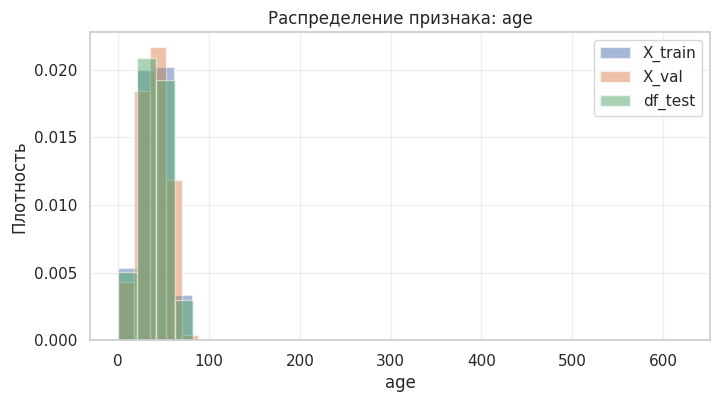

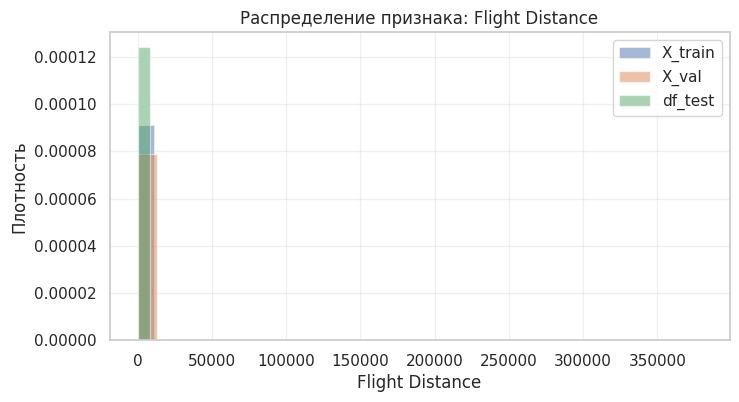

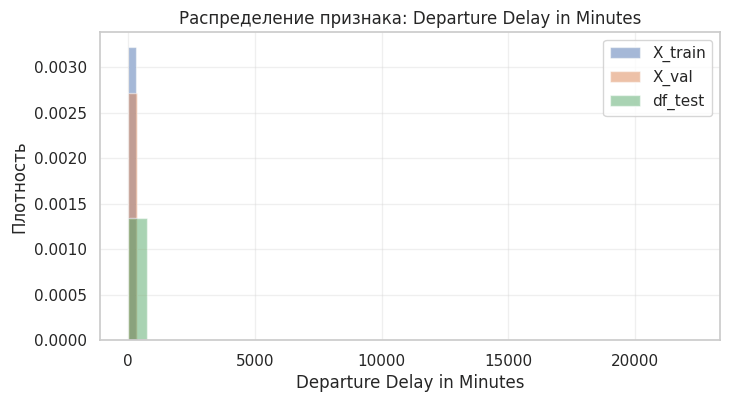

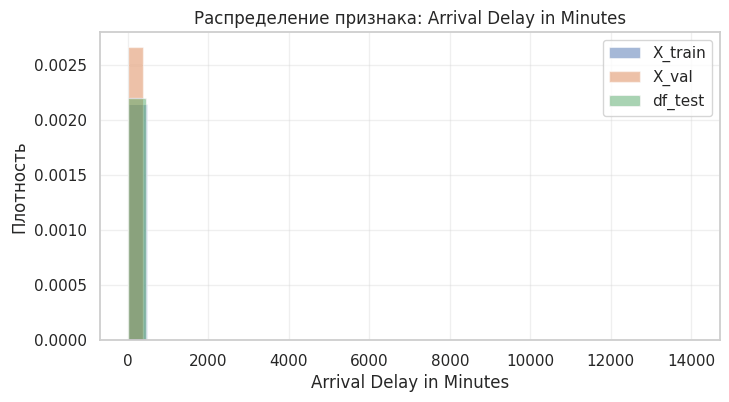

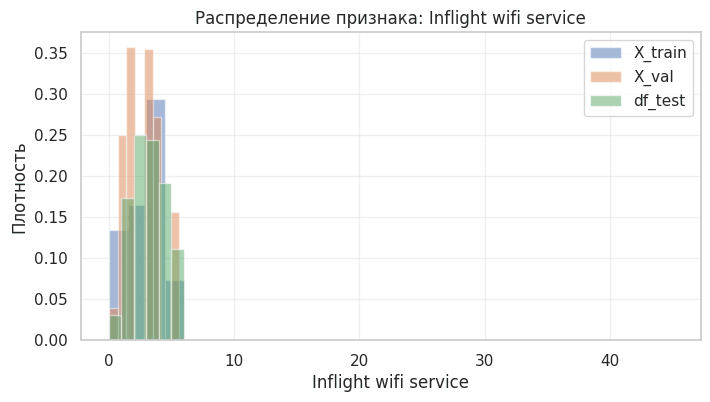

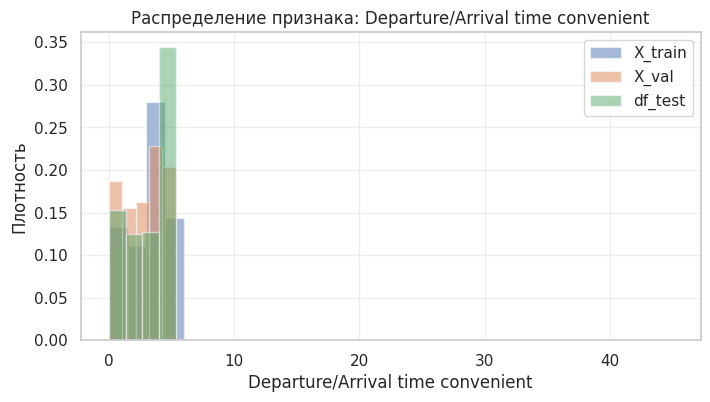

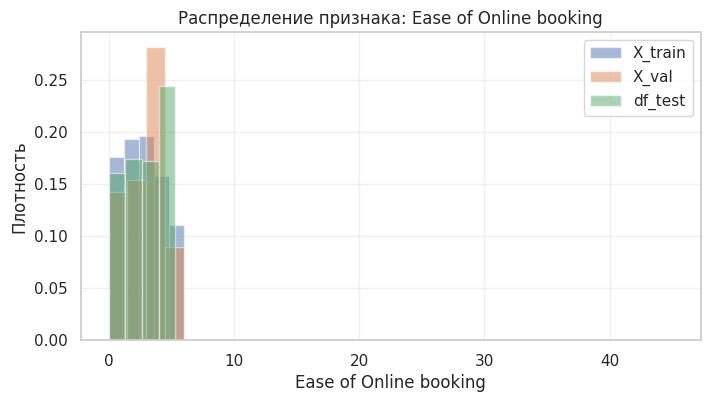

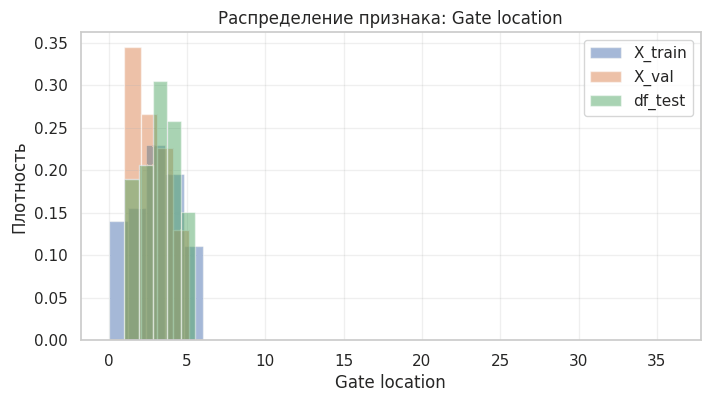

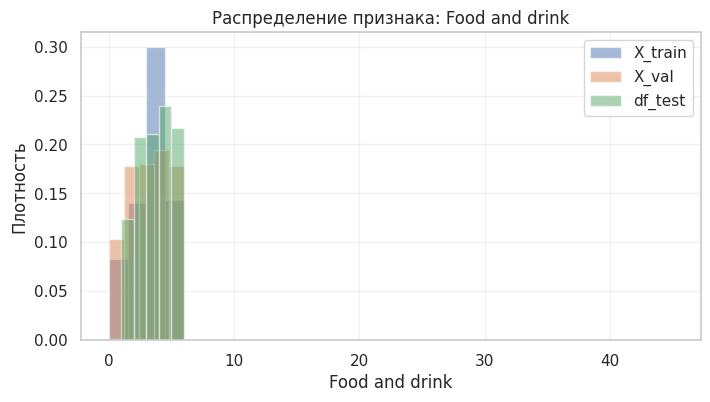

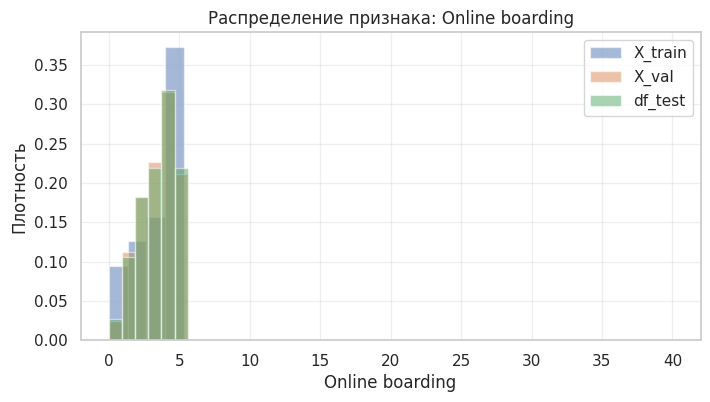

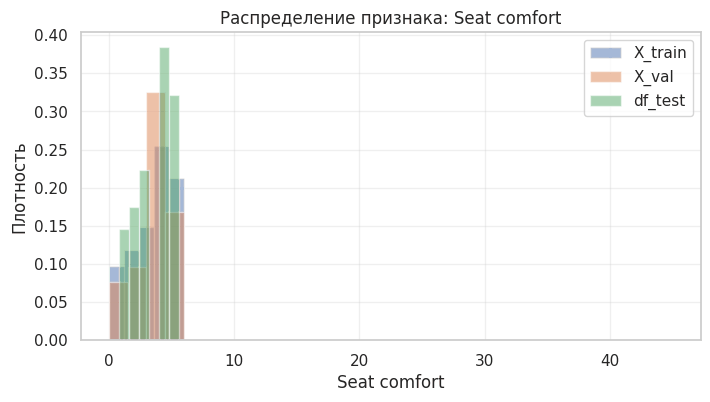

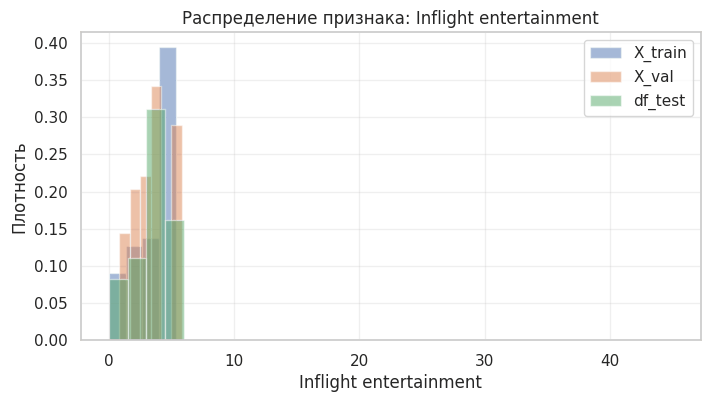

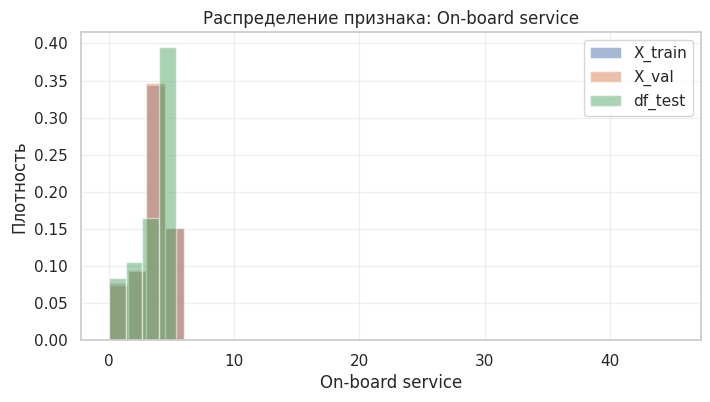

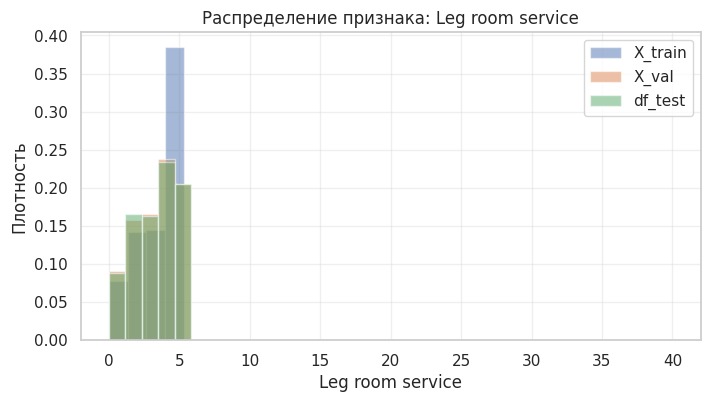

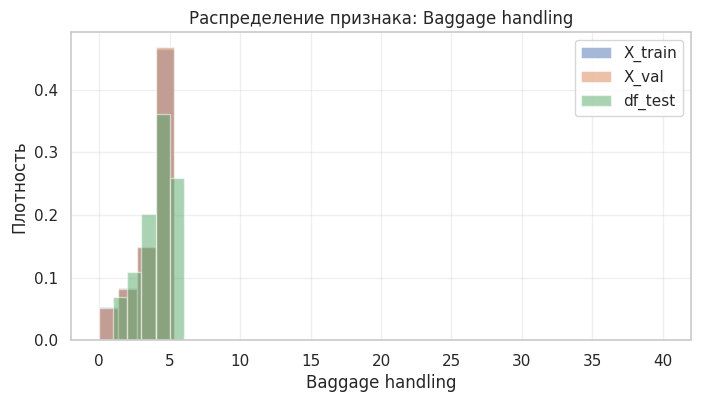

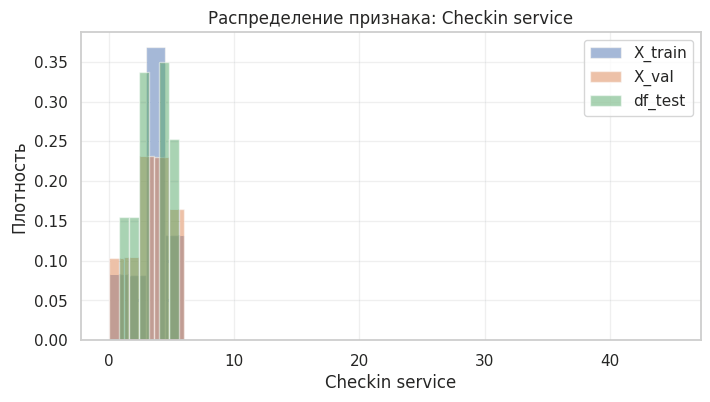

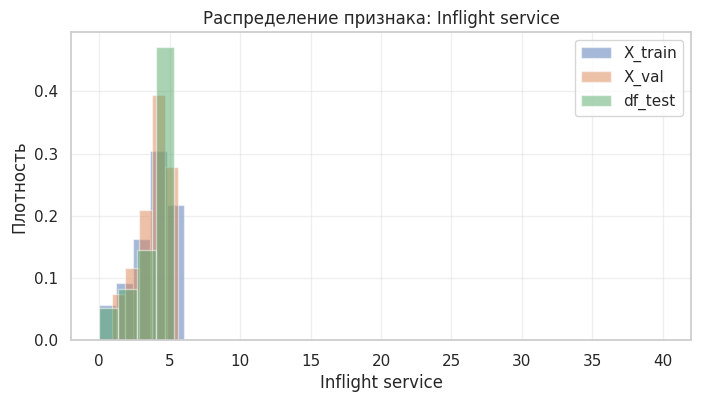

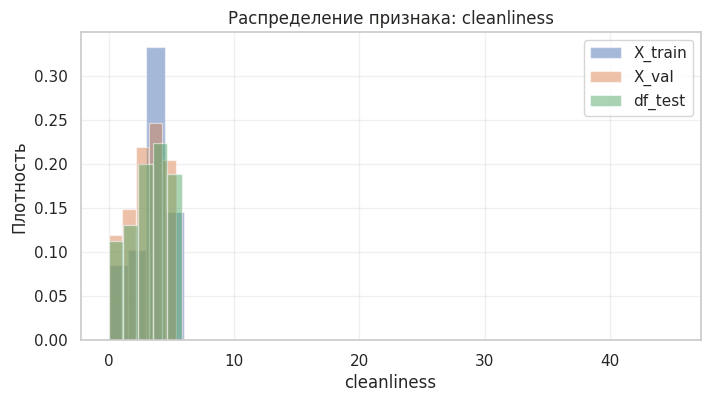

In [ ]:
for c in num_cols:
    plt.figure(figsize=(8, 4))
    plt.hist(X_train_nona[c], bins=30, alpha=0.5, label="X_train", density=True)
    plt.hist(X_val_nona[c], bins=30, alpha=0.5, label="X_val", density=True)
    plt.hist(df_test_nona[c], bins=30, alpha=0.5, label="df_test", density=True)
    plt.title(f"Распределение признака: {c}")
    plt.xlabel(c)
    plt.ylabel("Плотность")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

Видим, что есть крайне высокие значения, сильно выбивающиеся от абсолютного большинства данных

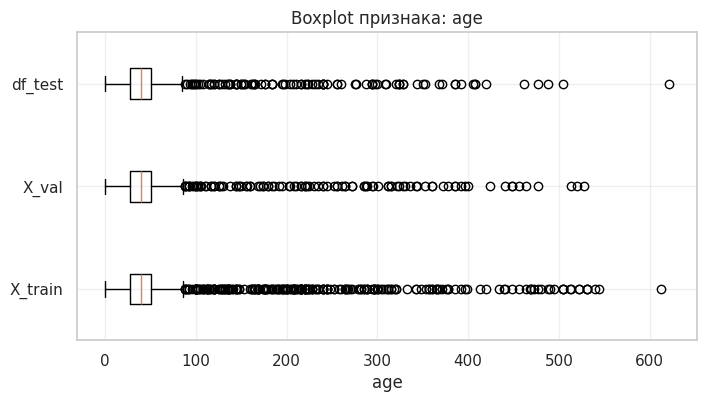

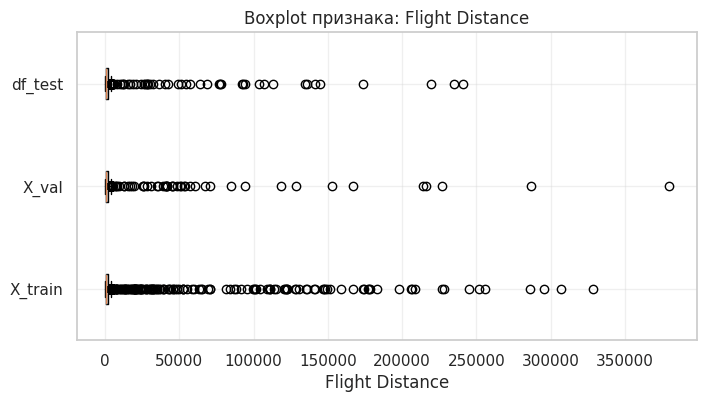

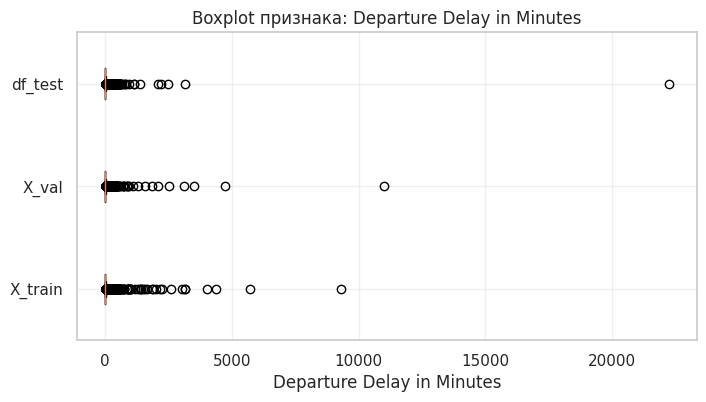

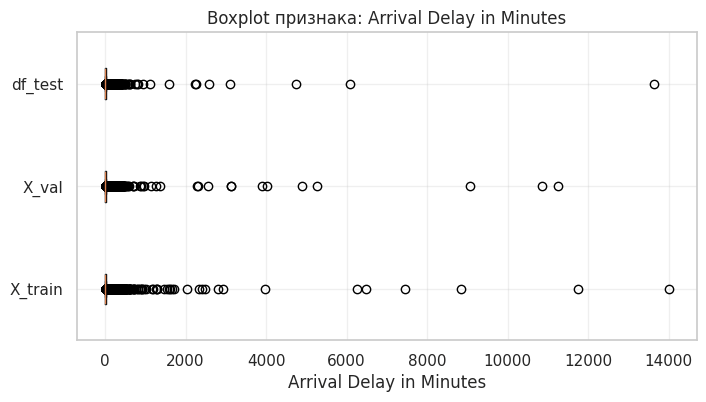

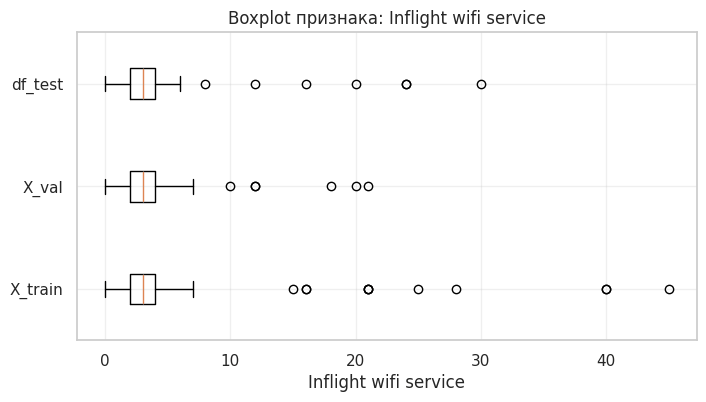

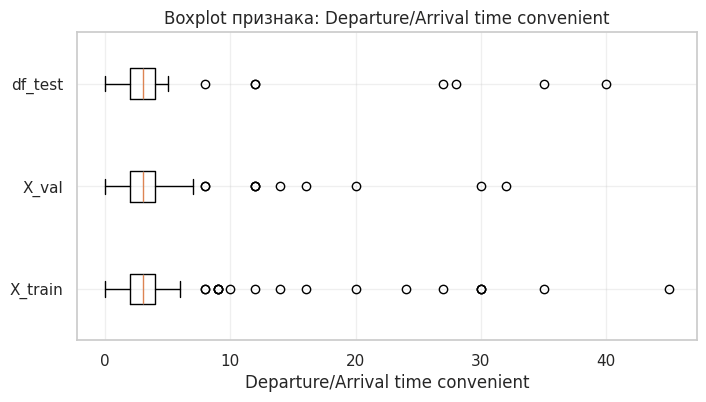

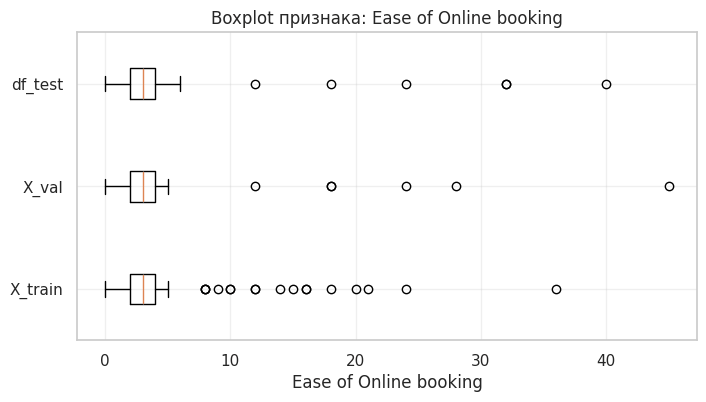

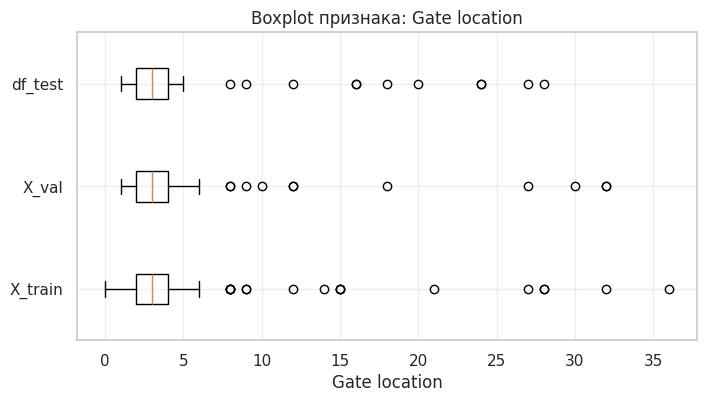

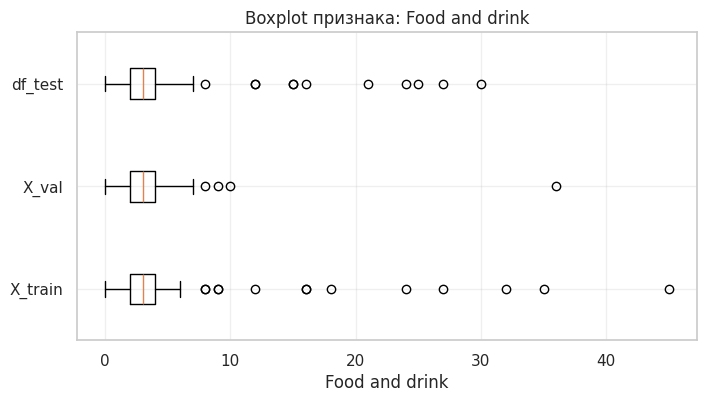

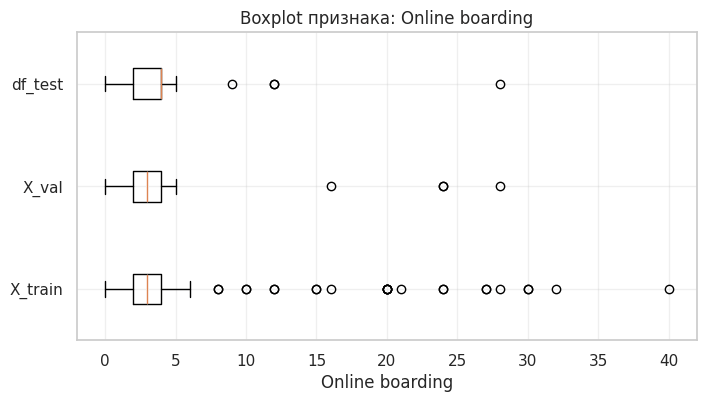

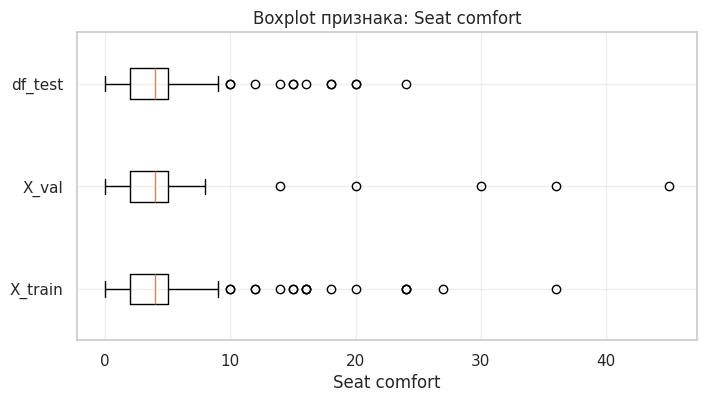

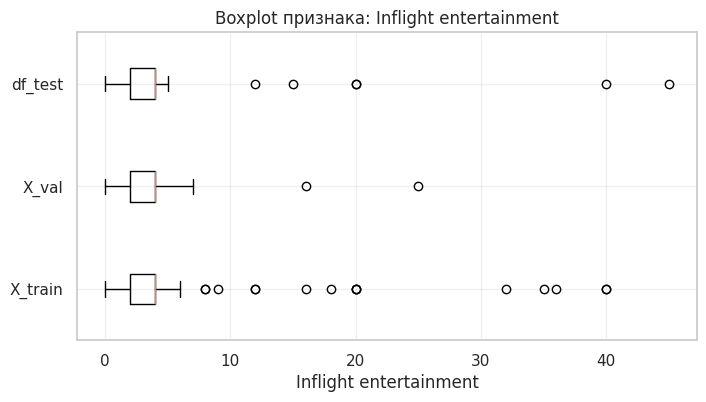

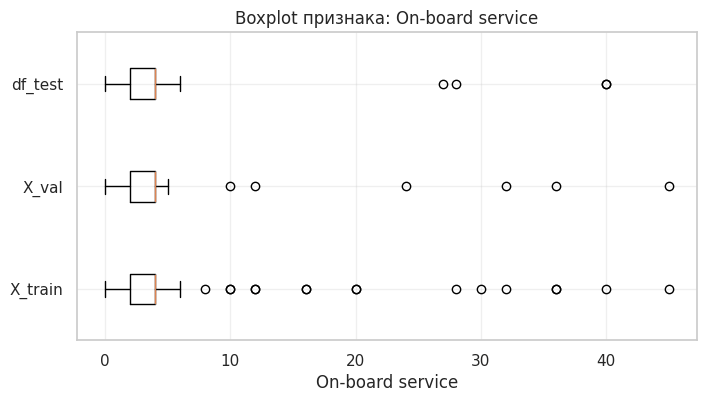

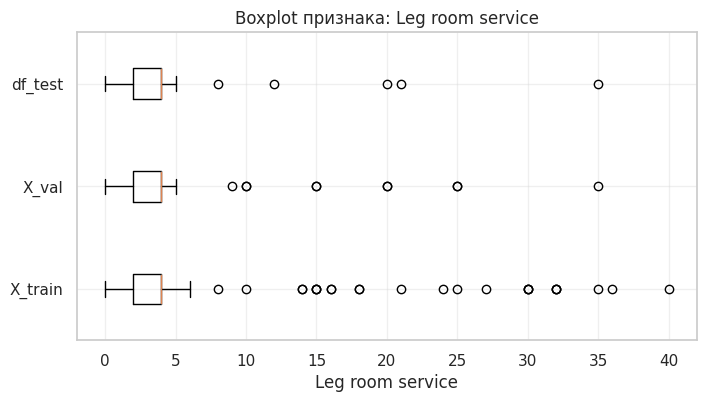

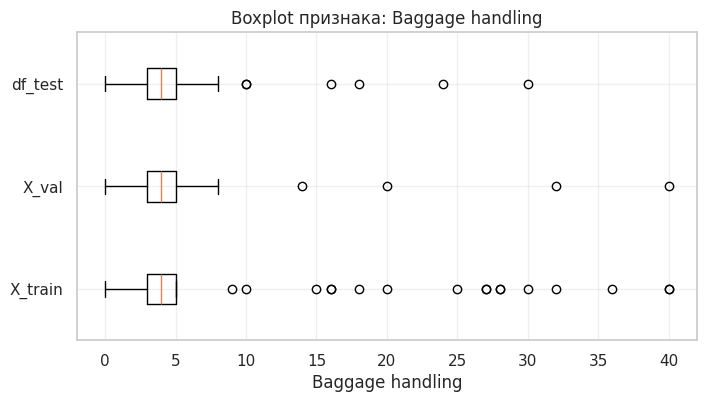

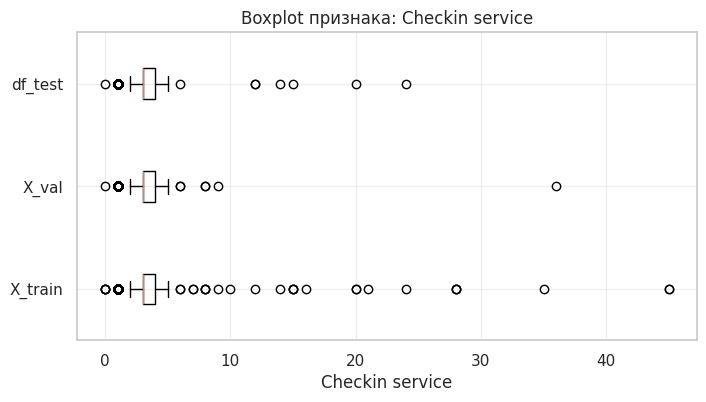

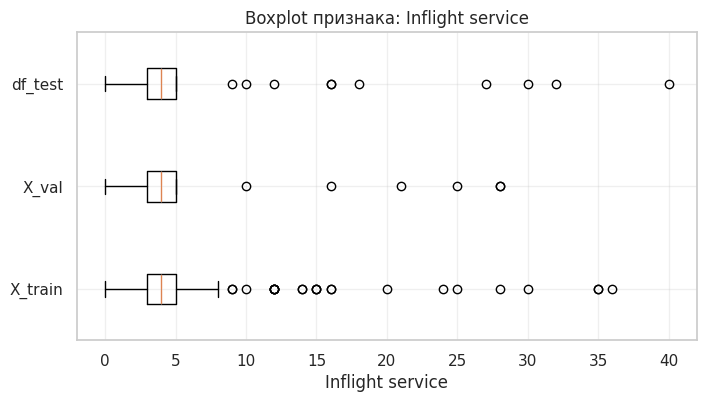

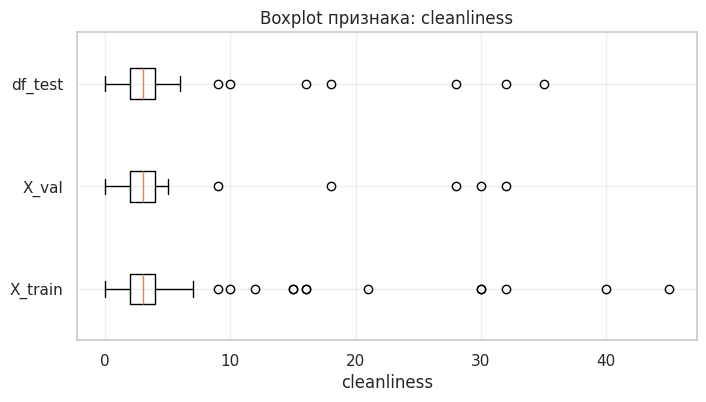

In [ ]:
for c in num_cols:
    plt.figure(figsize=(8, 4))
    plt.boxplot(
        [X_train_nona[c].dropna(), X_val_nona[c].dropna(), df_test_nona[c].dropna()],
        labels=["X_train", "X_val", "df_test"],
        vert=False
    )
    plt.title(f"Boxplot признака: {c}")
    plt.xlabel(c)
    plt.grid(alpha=0.3)
    plt.show()

в основном их не так много, мы можем обработать их так же, как пропуски

In [ ]:
def replace_with_mode(df, fill_values, rating_cols, age_col="age"):
    df = df.copy()

    # возраст: всё, что <0 или >120, заменяем на моду
    df.loc[(df[age_col] < 0) | (df[age_col] > 120), age_col] = fill_values[age_col]

    # рейтинги: всё, что вне [0, 5], заменяем на моду соответствующего признака
    for c in rating_cols:
        mask = (df[c] < 0) | (df[c] > 5)
        df.loc[mask, c] = fill_values[c]

    return df

X_train_clean = replace_with_mode(X_train_nona, fill_values, rating_cols)
X_val_clean = replace_with_mode(X_val_nona, fill_values, rating_cols)
df_test_clean = replace_with_mode(df_test_nona, fill_values, rating_cols)

заменим чрезвычайно большие значения в задержках и расстоянии на 99ый перцентиль, чтобы убрать только крайне редкие и мало реалистичные значения

In [ ]:
cols = ["Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]

upper_bounds = {}
for c in cols:
    upper_bounds[c] = X_train_clean[c].quantile(0.99)

upper_bounds

{'Flight Distance': np.float64(3903.0),
 'Departure Delay in Minutes': np.float64(184.0),
 'Arrival Delay in Minutes': np.float64(185.0)}

In [ ]:
def upper_bound(df, upper_bounds):
    df = df.copy()
    for c, ub in upper_bounds.items():
        df[c] = df[c].clip(upper=ub)
    return df

X_train_final = upper_bound(X_train_clean, upper_bounds)
X_val_final = upper_bound(X_val_clean, upper_bounds)
df_test_final = upper_bound(df_test_clean, upper_bounds)

**коммент**

- исследуем на корреляцию, чтобы посмотреть если ли сильная взаимосвязь между числовыми признаками

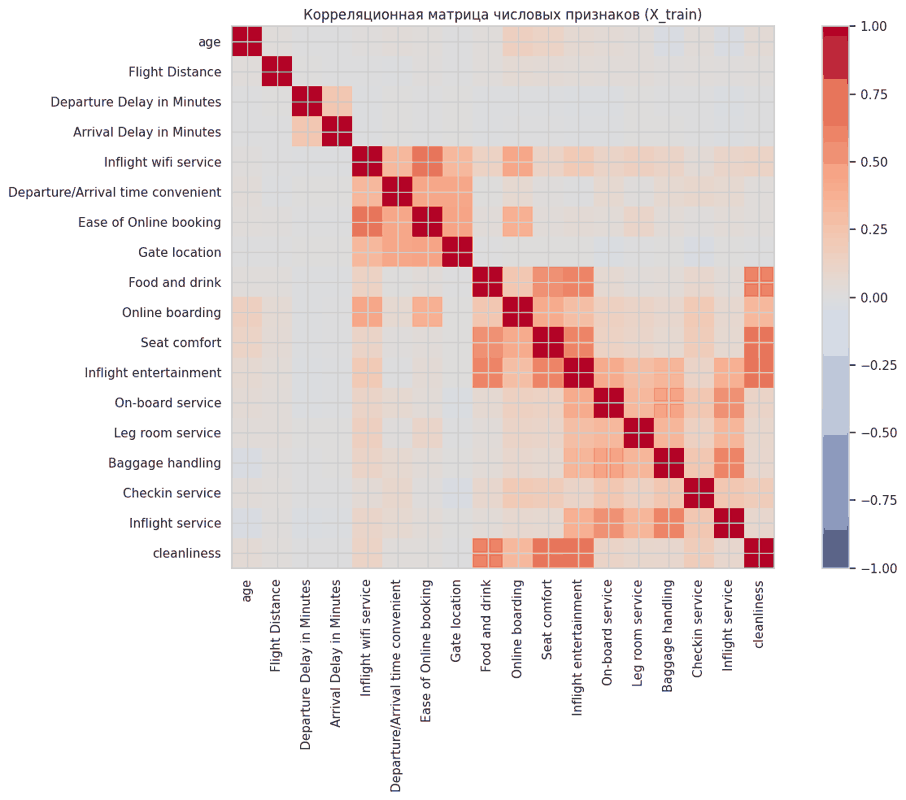

In [ ]:
corr_train = X_train_nona[num_cols].corr()

plt.figure(figsize=(14, 10))
plt.imshow(corr_train, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(num_cols)), num_cols, rotation=90)
plt.yticks(range(len(num_cols)), num_cols)
plt.title("Корреляционная матрица числовых признаков (X_train)")
plt.tight_layout()
plt.show()

In [ ]:
corr = corr_train.abs()
mask = np.triu(np.ones(corr.shape), k=1).astype(bool)
corr_unique = corr.where(mask).stack().sort_values(ascending=False)
print(corr_unique.head(20))

Inflight wifi service              Ease of Online booking    0.691860
Inflight entertainment             cleanliness               0.656114
Seat comfort                       cleanliness               0.646831
Food and drink                     cleanliness               0.631002
                                   Inflight entertainment    0.596260
Baggage handling                   Inflight service          0.586024
Seat comfort                       Inflight entertainment    0.581668
Food and drink                     Seat comfort              0.550643
On-board service                   Inflight service          0.517436
                                   Baggage handling          0.486816
Ease of Online booking             Gate location             0.442282
Inflight wifi service              Online boarding           0.428339
Departure/Arrival time convenient  Gate location             0.427863
                                   Ease of Online booking    0.422852
Online boarding     

посмотрим на распределение данных уже без аномальных значений

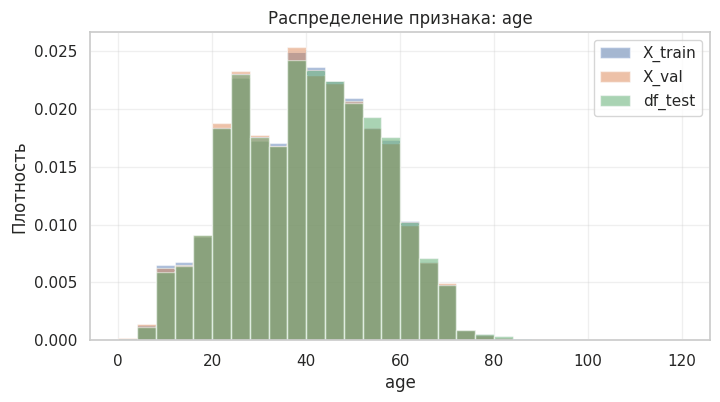

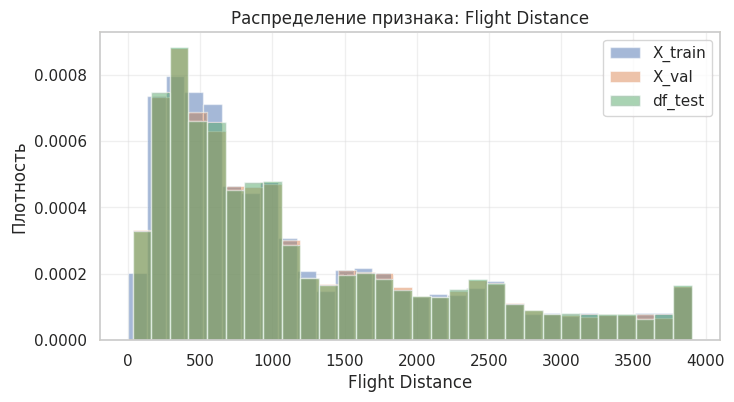

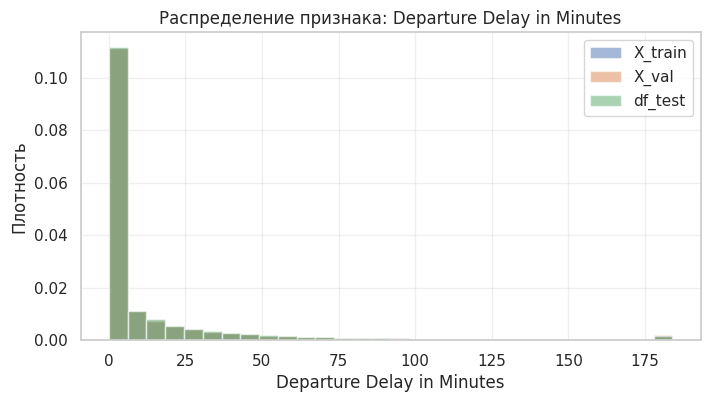

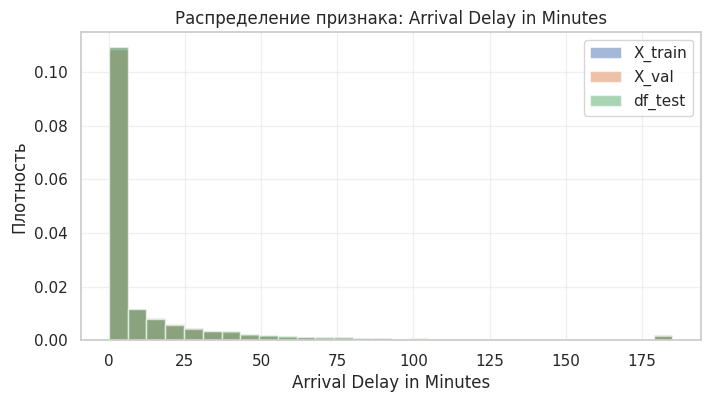

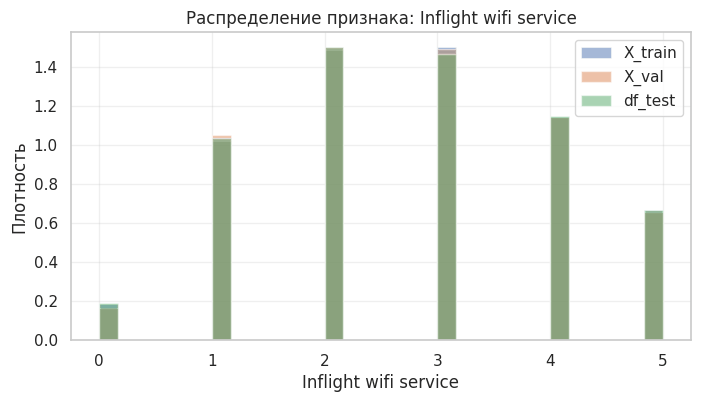

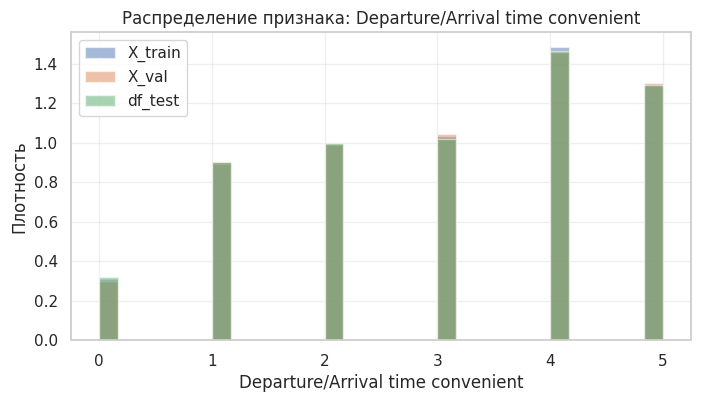

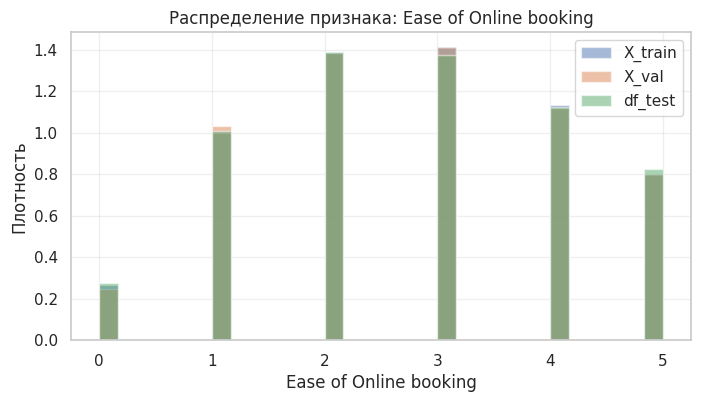

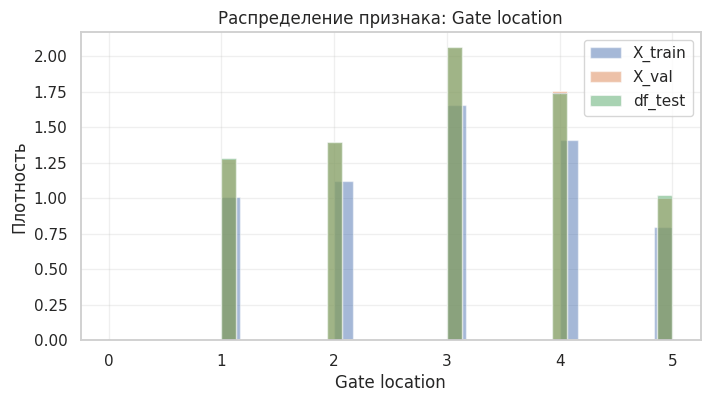

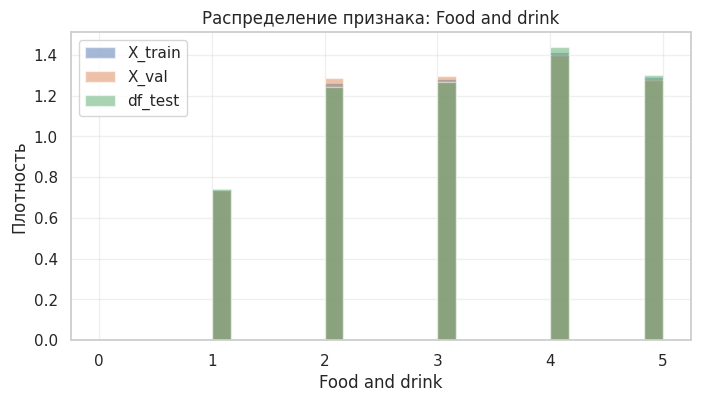

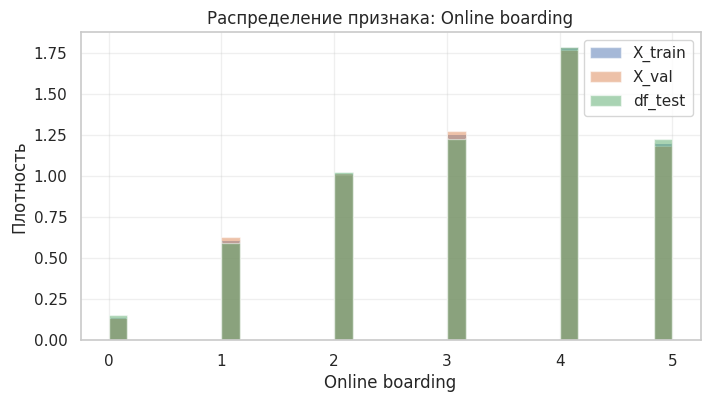

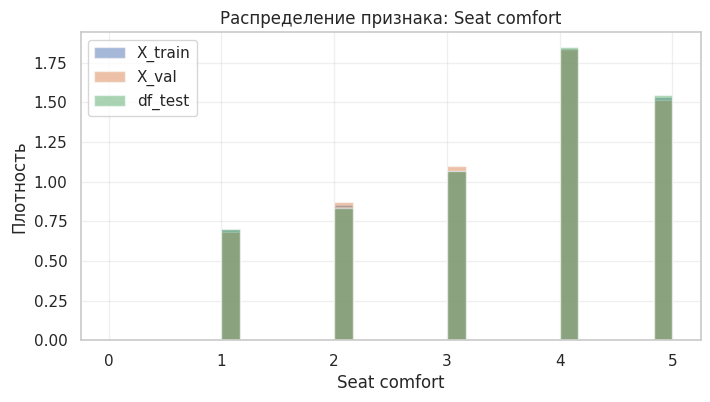

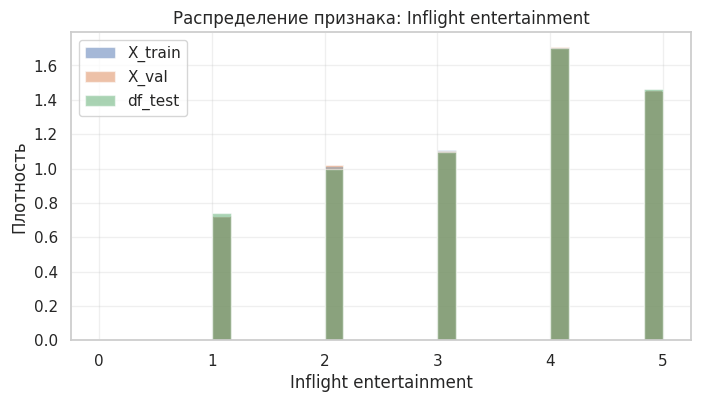

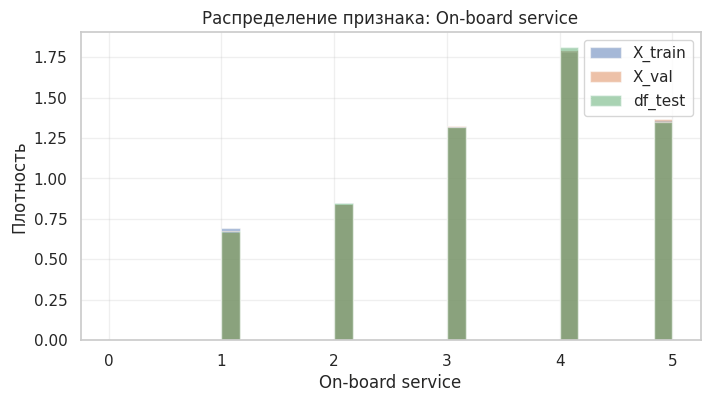

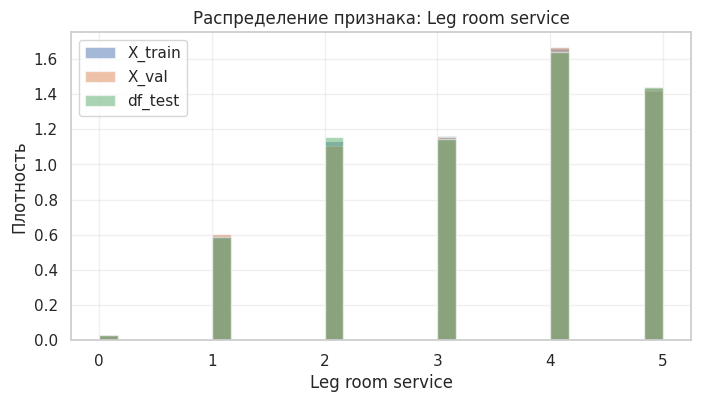

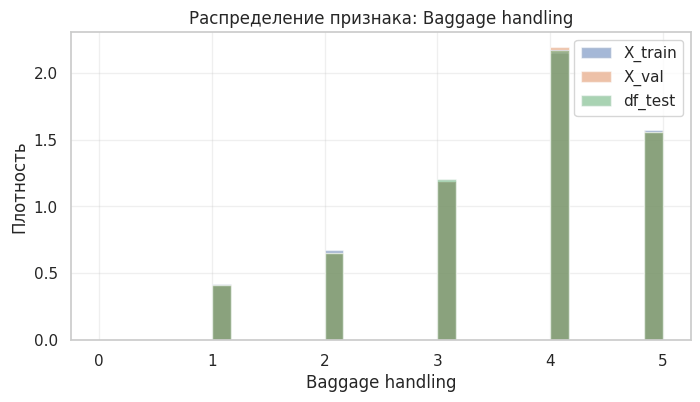

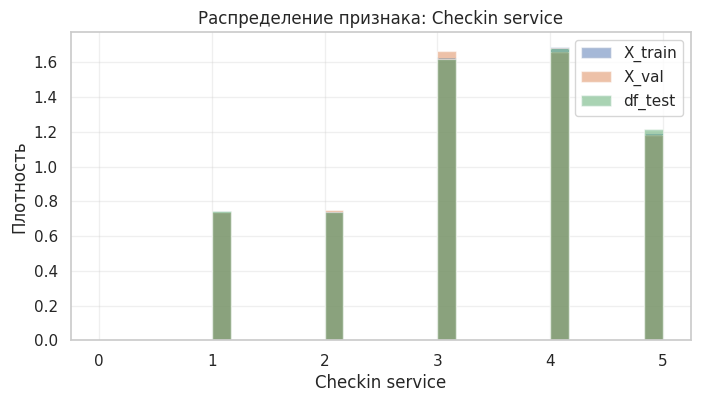

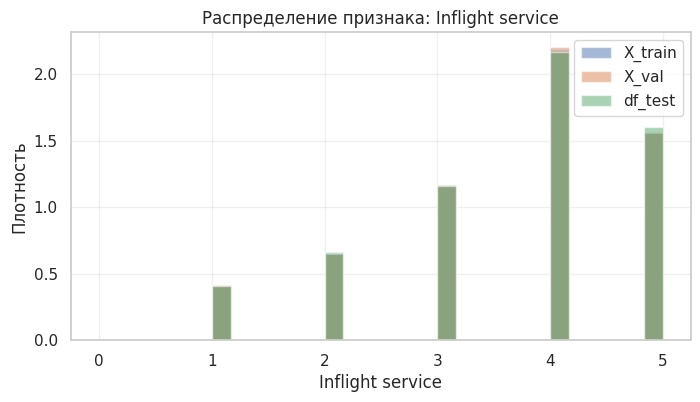

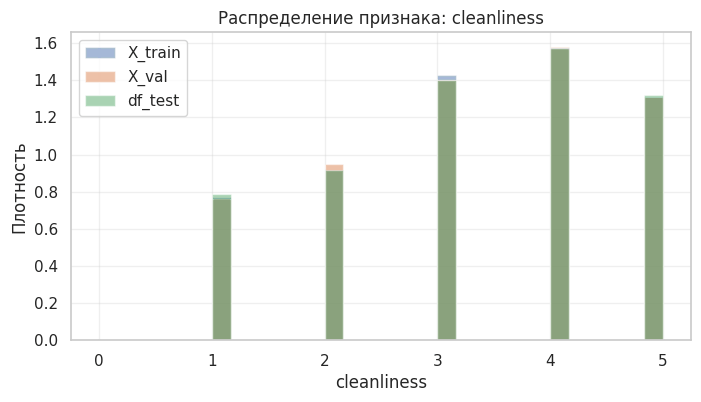

In [ ]:
for c in num_cols:
    plt.figure(figsize=(8, 4))
    plt.hist(X_train_final[c], bins=30, alpha=0.5, label="X_train", density=True)
    plt.hist(X_val_final[c], bins=30, alpha=0.5, label="X_val", density=True)
    plt.hist(df_test_final[c], bins=30, alpha=0.5, label="df_test", density=True)
    plt.title(f"Распределение признака: {c}")
    plt.xlabel(c)
    plt.ylabel("Плотность")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

**Вывод**
- аномалии были обработаны
- в датасетах признаки с умеренной и меньшей корреляцией:
  - похожие аспекты качества сервиса оцениваются схожим образом
  - если пассажир доволен чистотой, он часто лучше оценивает и развлечения, и комфорт, и питание
  - сервисные признаки образуют содержательно связанные группы
  - для интерпретации в дальнейшем важно помнить, что часть признаков несет близкую информацию
- по гистограммам видно, что формы распределений совпадают, а плотности практически накладываются друг на друга
- возраст: в основном летают клиенты от 20 до 60, есть какое-то количество старожилов за 100, которые являются редкостью, но могут быть реальными клиентами, в основном распределение нормальное
- расстояние полета: распределение правосторонне скошено, есть правый хвост: большинство перелетов сравнительно короткие или средние, а длинные перелеты встречаются реже
- задержки в минутах: распределение правосторонне скошено: большинство перелетов сравнительно короткие или средние, а длинные перелеты встречаются реже, оба признака коррелируют, что логично, если задрживается отлет, то и прилет тоже
- рейтинги: чаще всего встречаются оценки 3, 4 и 5; низкие оценки 0 и 1 встречаются заметно реже; в целом оценки средние или высокие по всем наборам данных

Закодируем категориальные признаки: будем для каждой модели кодировать по-разному:
- для своего дерева решений используем ordinal-кодирование, так как модель отдельно учитывает категориальный тип признака и обрабатывает его специальным образом
- для RandomForestClassifier применим ohe, так как sklearn-деревья не работают с категориальными признаками напрямую и при ordinal-кодировании могут воспринимать категории как упорядоченные значения

In [ ]:
X_train_dt = X_train_final.copy()
X_val_dt = X_val_final.copy()

ord = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train_dt[cat_cols] = ord.fit_transform(X_train_final[cat_cols])
X_val_dt[cat_cols] = ord.transform(X_val_final[cat_cols])

# все к float
X_train_dt = X_train_dt.astype(float)
X_val_dt = X_val_dt.astype(float)

In [ ]:
X_train_rf = X_train_final.copy()
X_val_rf = X_val_final.copy()

try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

X_train_cat_ohe = ohe.fit_transform(X_train_rf[cat_cols])
X_val_cat_ohe = ohe.transform(X_val_rf[cat_cols])

ohe_cols = ohe.get_feature_names_out(cat_cols)

X_train_cat_ohe = pd.DataFrame(X_train_cat_ohe, columns=ohe_cols, index=X_train_rf.index)
X_val_cat_ohe = pd.DataFrame(X_val_cat_ohe, columns=ohe_cols, index=X_val_rf.index)

X_train_num = X_train_rf[num_cols].copy()
X_val_num = X_val_rf[num_cols].copy()

X_train_rf = pd.concat([X_train_num, X_train_cat_ohe], axis=1)
X_val_rf = pd.concat([X_val_num, X_val_cat_ohe], axis=1)

# на всякий случай
X_train_rf = X_train_rf.astype(float)
X_val_rf = X_val_rf.astype(float)

также приведем целевую переменную к числовому значению

In [ ]:
y_train = y_train.map(lambda x: 1 if x == "satisfied" else 0).astype(int)
y_val = y_val.map(lambda x: 1 if x == "satisfied" else 0).astype(int)

### **Задание 12. (0.25 балла)**

- Обучите самописное дерево и Random Forest с базовыми гиперпараметрами. Выведите `f1-score`.

In [ ]:
feature_types = []
for c in X_train_dt.columns:
    if c in cat_cols:
        feature_types.append("categorical")
    else:
        feature_types.append("real")

dt = DecisionTree(feature_types=feature_types)

dt.fit(X_train_dt.to_numpy(), np.asarray(y_train.to_numpy()))
y_pred_dt = dt.predict(X_val_dt.to_numpy())

print('F1-score для своего дерева', round(f1_score(y_val, y_pred_dt), 4))

F1-score для своего дерева 0.9341


In [ ]:
rf = RandomForestClassifier(random_state=77)

rf.fit(X_train_rf, y_train)
y_pred_rf = rf.predict(X_val_rf)

print('F1-score для random forest:', round(f1_score(y_val, y_pred_rf), 4))

F1-score для random forest: 0.9549


Значения метрик по моделям получились высокие, вероятно, потому что признаки являются очень информативными, в особенности оценки сервиса, качество леса ожидаемо выше, так как оно меньше переобучается, устойчивее к шуму, лучше обобщает

### **Задание 13. (0.4 баллa)**

- Попробуйте подобрать оптимальные гиперпараметры леса и дерева (если реализовали их в бонусе), используя [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html).
- Сравните качество полученных моделей и выберите лучшую. Лучшую модель сохраните в pickle.

**Важно:**  

Хотя бы один из гиперпараметров перебирайте из распределения (например, `uniform` из `scipy.stats`)

так как RandomizedSearchCV работает только со sklearn-совместимыми estimator, нужна обертка

In [ ]:
class MyDecisionTreeWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, feature_types, max_depth=None, min_samples_split=2, min_samples_leaf=1):
        self.feature_types = feature_types
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf

    def fit(self, X, y):
        self.model_ = DecisionTree(
            feature_types=self.feature_types,
            max_depth=self.max_depth,
            min_samples_split=self.min_samples_split,
            min_samples_leaf=self.min_samples_leaf
        )
        self.model_.fit(np.asarray(X), np.asarray(y))
        return self

    def predict(self, X):
        return self.model_.predict(np.asarray(X))

In [ ]:
f1_scorer = make_scorer(f1_score)

In [ ]:
dt_feature_types = []
for c in X_train_dt.columns:
    if c in cat_cols:
        dt_feature_types.append("categorical")
    else:
        dt_feature_types.append("real")

dt_model = MyDecisionTreeWrapper(feature_types=dt_feature_types)

dt_param_dist = {
    "max_depth": [None] + list(range(2, 21)),
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(1, 10)
}

dt_search = RandomizedSearchCV(
    estimator=dt_model,
    param_distributions=dt_param_dist,
    n_iter=30,
    scoring=f1_scorer,
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

dt_search.fit(X_train_dt, y_train)

print("Лучшие параметры DT:", dt_search.best_params_)
print("Лучший CV F1-score DT:", dt_search.best_score_)

best_dt = dt_search.best_estimator_
dt_val_pred = best_dt.predict(X_val_dt)
dt_val_f1 = f1_score(y_val, dt_val_pred)

print("F1-score лучшего дерева на validation:", round(dt_val_f1, 4))

Fitting 3 folds for each of 30 candidates, totalling 90 fits
Лучшие параметры DT: {'max_depth': 13, 'min_samples_leaf': 2, 'min_samples_split': 16}
Лучший CV F1-score DT: 0.94064084248615
F1-score лучшего дерева на validation: 0.9438


In [ ]:
rf = RandomForestClassifier(random_state=77)

rf_param_dist = {
    "n_estimators": randint(300, 1000),
    "max_depth": [None, 8, 10, 12, 15, 20, 25, 30],
    "min_samples_split": [4, 6, 8, 10, 12, 15],
    "min_samples_leaf": randint(1, 6),
    "max_features": ["sqrt", "log2", 0.3, 0.5, 0.7],
    "bootstrap": [True, False]
}

rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rf_param_dist,
    n_iter=40,
    scoring=f1_scorer,
    cv=5,
    random_state=77,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train_rf, y_train)

print("Лучшие параметры RF:", rf_search.best_params_)
print("Лучший CV F1-score RF:", rf_search.best_score_)

best_rf = rf_search.best_estimator_
rf_val_pred = best_rf.predict(X_val_rf)
rf_val_f1 = f1_score(y_val, rf_val_pred)

print("F1-score лучшего Random Forest на validation:", round(rf_val_f1, 4))

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Лучшие параметры RF: {'bootstrap': False, 'max_depth': 30, 'max_features': 0.5, 'min_samples_leaf': 1, 'min_samples_split': 8, 'n_estimators': 489}
Лучший CV F1-score RF: 0.9570692752564491
F1-score лучшего Random Forest на validation: 0.957


после подбора гиперпараметров качества своего дерево увеличилось больше, чем качество random forest

Ожидаемо, качество леса лучше, чем одного дерева, поэтому лучшей моделью является random forest

In [ ]:
best_model = best_rf

with open("best_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

print("Лучшая модель сохранена в best_model.pkl")

Лучшая модель сохранена в best_model.pkl


### **Задание 14. Анализ моделей (0.1 балла)**

- Отобразите`feature_importances_` вашего лучшего случайного леса;
- Проанализируйте, какие признаки оказались важными?

                                 importance
Online boarding                    0.265540
Inflight wifi service              0.173408
class_Business                     0.084153
Type of Travel_Business travel     0.058493
Type of Travel_Personal Travel     0.051444
Inflight entertainment             0.045316
class_Eco                          0.037910
Seat comfort                       0.026548
Ease of Online booking             0.026046
Checkin service                    0.022534
Leg room service                   0.021856
age                                0.020976
Customer Type_Loyal Customer       0.020400
Customer Type_disloyal Customer    0.019136
Inflight service                   0.019027
Flight Distance                    0.018261
Baggage handling                   0.017146
cleanliness                        0.014519
On-board service                   0.014259
Gate location                      0.013662

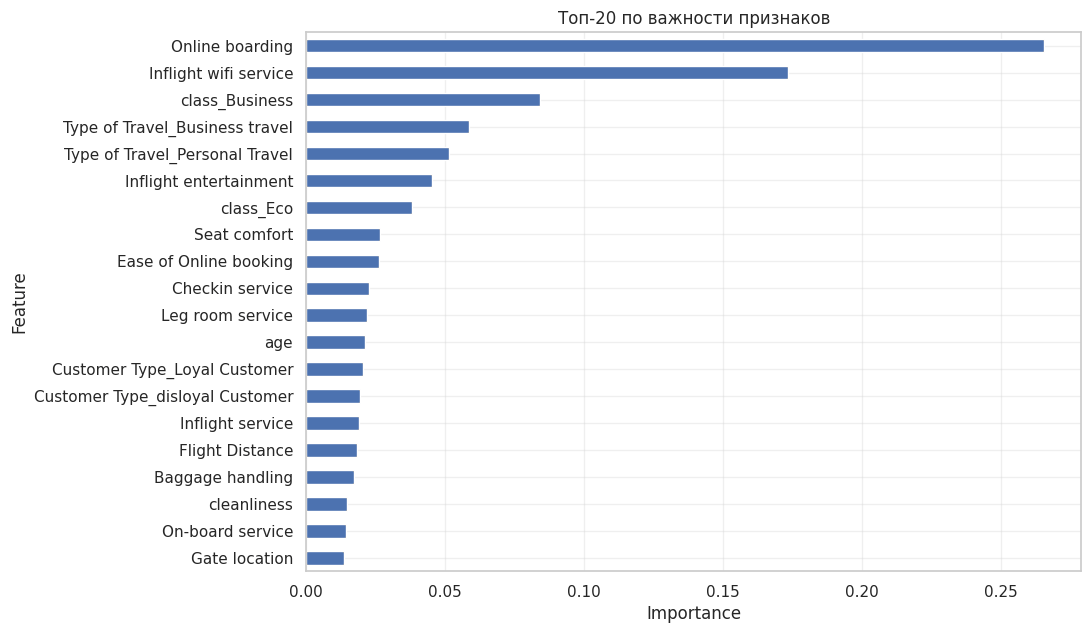

In [ ]:
importances = pd.Series(best_model.feature_importances_, index=X_train_rf.columns)
importances = importances.sort_values(ascending=False)

display(importances.head(20).to_frame("importance"))

plt.figure(figsize=(10, 7))
importances.head(20).sort_values().plot(kind="barh")
plt.title("Топ-20 по важности признаков")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.grid(alpha=0.3)
plt.show()

важным для клиентов оказалось:
- качество онлайн-регистрации/посадки,
- качество Wi-Fi на борту,
- класс обслуживания,
- тип поездки,
- развлечения на борту

то есть удовлетворенность пассажира сильно зависит от качества сервиса, класса перелета и того, летит ли он по бизнес или личным делам, что логично

указанные признаки чаще и полезнее использоватьлись при разбиении данных

чтобы посмотреть на направление влияния и вклад признаков посмотрим на другие способы интерпретации

### **Задание 15. (0.25 балла)**
- Интерпретируйте важности признаков с помощью SHAP.
- Опишите полученый график

**Важно:** Для подсчета используйте 1000 случайных объектов, иначе не дождетесь за приемлемое время

**Вам может помочь:** [Статья "Интерпретация моделей и диагностика сдвига данных: LIME, SHAP и Shapley Flow"](https://habr.com/ru/company/ods/blog/599573/) из блога ods.ai на Хабре

In [ ]:
X_shap = X_train_rf.sample(n=1000, random_state=42)
print(X_shap.shape)

(1000, 27)


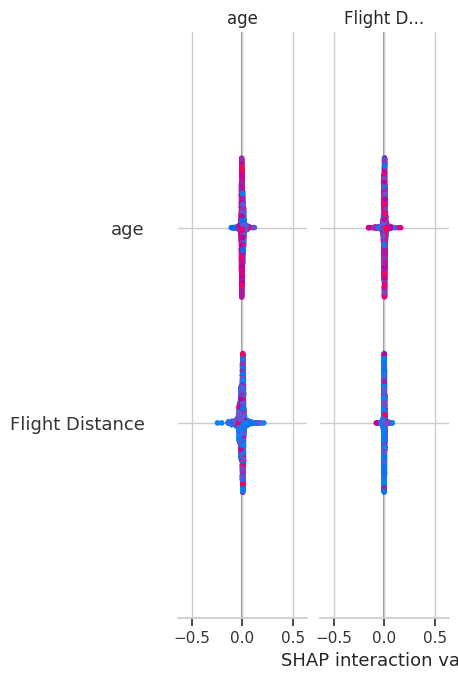

In [ ]:
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_shap)

if isinstance(shap_values, list):
    shap.summary_plot(shap_values[1], X_shap, show=True)
else:
    shap.summary_plot(shap_values, X_shap, show=True)

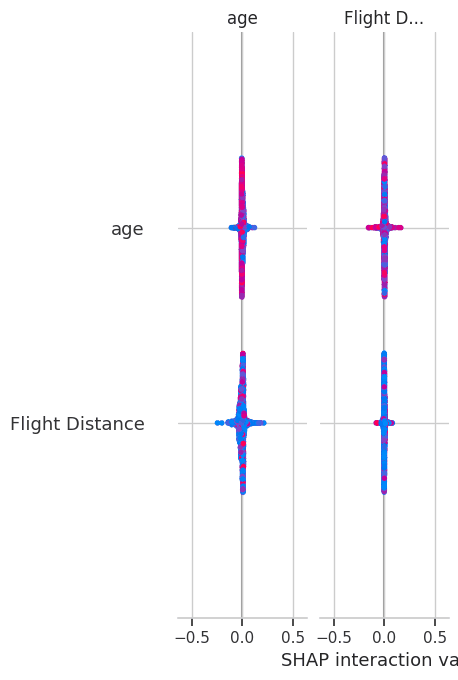

In [ ]:
if isinstance(shap_values, list):
    shap.summary_plot(shap_values[1], X_shap, plot_type="bar", show=True)
else:
    shap.summary_plot(shap_values, X_shap, plot_type="bar", show=True)

значимые признаки совпадают с feauture importance, можно оценить в какую сторону признаки влияют на прогноз и насколько сильно отдельные значения признаков двигают модель к определенному классу, то есть вклад

- подтверждается большая важность wifi и онлайн регистрации
- бизнес-класс и бизнес-поездка сильно влияют на вероятность удовлетворенности клиента
- сервисные признаки (Inflight entertainment, Seat comfort, Checkin service, Inflight service, cleanliness) дают дополнительный вклад

### **Задание 16. (0.25 балла)**

- Интерпретируйте важности признаков для одного прогноза с помощью LIME;
- Опишите полученный график для выбранного наблюдения

In [ ]:
class_names = ["neutral or dissatisfied", "satisfied"]

lime_explainer = LimeTabularExplainer(
    training_data=X_train_rf.to_numpy(),
    feature_names=X_train_rf.columns.tolist(),
    class_names=class_names,
    mode="classification"
)

In [ ]:
#первый объект
i = 0

x_instance = X_val_rf.iloc[i].to_numpy()
true_label = y_val.iloc[i] if hasattr(y_val, "iloc") else y_val[i]
pred_label = best_model.predict(X_val_rf.iloc[[i]])[0]
pred_proba = best_model.predict_proba(X_val_rf.iloc[[i]])[0]

print("Истинный класс:", true_label)
print("Предсказанный класс:", pred_label)
print("Вероятности классов:", pred_proba)

Истинный класс: 1
Предсказанный класс: 1
Вероятности классов: [0. 1.]


In [ ]:
lime_exp = lime_explainer.explain_instance(
    data_row=x_instance,
    predict_fn=best_model.predict_proba,
    num_features=15
)

lime_exp.show_in_notebook(show_table=True)

<IPython.core.display.HTML object>

In [ ]:
lime_list = lime_exp.as_list()
lime_df = pd.DataFrame(lime_list, columns=["feature_condition", "weight"])
display(lime_df)

                                feature_condition    weight
0   0.00 < Type of Travel_Business travel <= 1.00  0.183913
1          Type of Travel_Personal Travel <= 0.00  0.164530
2                   Inflight wifi service <= 2.00 -0.132924
3         Customer Type_disloyal Customer <= 0.00  0.105896
4                 4.00 < Baggage handling <= 5.00  0.060323
5                          Checkin service > 4.00  0.055229
6                 4.00 < Inflight service <= 5.00  0.048800
7                     4.00 < Seat comfort <= 5.00  0.043209
8                  3.00 < Online boarding <= 4.00  0.030316
9                Arrival Delay in Minutes > 13.00 -0.025122
10                             cleanliness > 4.00  0.022234
11                        On-board service > 4.00  0.021243
12                 Ease of Online booking <= 2.00 -0.020809
13                          Gate location <= 2.00  0.019907
14                      Flight Distance > 1744.00 -0.015681

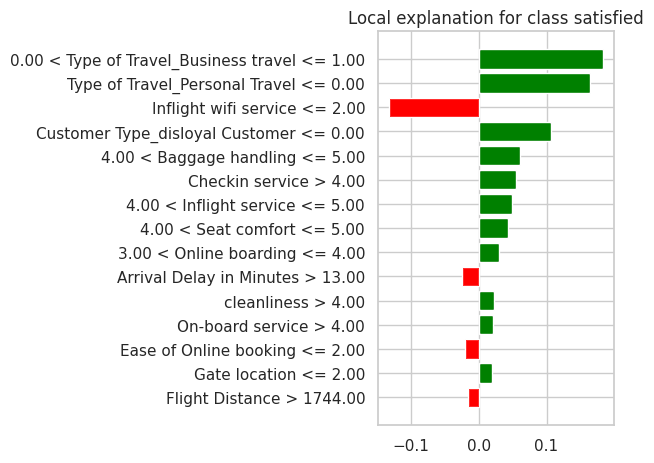

In [ ]:
fig = lime_exp.as_pyplot_figure()
plt.tight_layout()
plt.show()

было предсказано, что первый клиент удовлетворен с очень высокой уверенностью

для конкретного пассажира получается:
- плюсы:
  - бизнес-поездка,
  - вероятно постоянный клиент,
  - высокие оценки сервиса,  багажа, check-in, чистоты и комфорта
- минусы:
  - слабый Wi-Fi,
  - задержка прилёта,
  - слабая онлайн-бронь,
  - долгий перелет

плюсы перевешивают минусы

# Обратная связь

Расскажите, как вам это домашнее задание. Было ли оно полезным? Научились ли вы чему то? Насколько сложным по 10-балльной шкале оно вам показалось? Сколько времени у вас ушло на его выполнение? Что следовало ещё в него включить? Было ли что-то лишнее?

задание было полезным!